# Price Prediction for Mobile Phones

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## Load dataset

In [11]:
df = pd.read_excel(r"C:\Users\HP\Desktop\Python\Processed_Flipdata.xlsx")

In [13]:
print(df.shape)

(541, 12)


In [14]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     541 non-null    int64  
 1   Model          541 non-null    object 
 2   Colour         541 non-null    object 
 3   Memory         541 non-null    int64  
 4   RAM            541 non-null    int64  
 5   Battery_       541 non-null    int64  
 6   Rear Camera    541 non-null    object 
 7   Front Camera   541 non-null    object 
 8   AI Lens        541 non-null    int64  
 9   Mobile Height  541 non-null    float64
 10  Processor_     541 non-null    object 
 11  Prize          541 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 50.8+ KB
None


In [15]:
print(df.columns)

Index(['Unnamed: 0', 'Model', 'Colour', 'Memory', 'RAM', 'Battery_',
       'Rear Camera', 'Front Camera', 'AI Lens', 'Mobile Height', 'Processor_',
       'Prize'],
      dtype='object')


In [16]:
print(df.head(10))

   Unnamed: 0            Model         Colour  Memory  RAM  Battery_  \
0           0  Infinix SMART 7    Night Black      64    4      6000   
1           1  Infinix SMART 7     Azure Blue      64    4      6000   
2           2     MOTOROLA G32   Mineral Gray     128    8      5000   
3           3         POCO C50     Royal Blue      32    2      5000   
4           4  Infinix HOT 30i       Marigold     128    8      5000   
5           5  Infinix HOT 30i   Glacier Blue     128    8      5000   
6           6  Infinix HOT 30i   Mirror Black     128    8      5000   
7           7  Infinix HOT 30i  Diamond White     128    8      5000   
8           8  Infinix HOT 30i  Diamond White      64    4      5000   
9           9  Infinix HOT 30i   Mirror Black      64    4      5000   

  Rear Camera Front Camera  AI Lens  Mobile Height  \
0        13MP          5MP        1          16.76   
1        13MP          5MP        1          16.76   
2        50MP         16MP        0          

In [17]:
print(df.tail(10))

     Unnamed: 0                  Model           Colour  Memory  RAM  \
531         628          OPPO F21s Pro  Starlight Black     128    8   
532         631        APPLE iPhone 12             Blue      64    8   
533         632     SAMSUNG Galaxy A13            Peach     128    6   
534         633         Nokia G11 Plus             Grey      64    4   
535         636    SAMSUNG Galaxy A04e       Light Blue      64    3   
536         637  SAMSUNG Galaxy S23 5G            Cream     256    8   
537         638               LAVA Z21             Cyan      32    2   
538         639         Tecno Spark 8T   Turquoise Cyan      64    4   
539         641  SAMSUNG Galaxy A54 5G     Awesome Lime     128    8   
540         642               OPPO A77         Sky Blue     128    4   

     Battery_ Rear Camera Front Camera  AI Lens  Mobile Height  \
531      4500        64MP         16MP        0          16.33   
532      2815        12MP         12MP        0          15.49   
533      

In [18]:
missing = df.isnull().sum()

print(missing)

Unnamed: 0       0
Model            0
Colour           0
Memory           0
RAM              0
Battery_         0
Rear Camera      0
Front Camera     0
AI Lens          0
Mobile Height    0
Processor_       0
Prize            0
dtype: int64


In [20]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


 ## The dataset contains 541 mobile-phone records with numerical and categorical variables

# (A) Univariate Analysis

### The main numerical variables are:

In [21]:
numeric_cols = df.select_dtypes(include=np.number).columns

print(df[numeric_cols].describe().T)

               count          mean           std    min      25%       50%  \
Unnamed: 0     541.0    289.711645    182.359185    0.0   135.00    273.00   
Memory         541.0    110.550832     60.600694   16.0    64.00    128.00   
RAM            541.0      5.397412      1.984923    2.0     4.00      6.00   
Battery_       541.0   4871.587800    780.148862  800.0  5000.00   5000.00   
AI Lens        541.0      0.062847      0.242911    0.0     0.00      0.00   
Mobile Height  541.0     16.431201      2.523553    4.5    16.51     16.71   
Prize          541.0  16228.375231  10793.588322  920.0  9290.00  13499.00   

                    75%       max  
Unnamed: 0       434.00    642.00  
Memory           128.00    256.00  
RAM                8.00      8.00  
Battery_        5000.00   7000.00  
AI Lens            0.00      1.00  
Mobile Height     16.94     41.94  
Prize          19280.00  80999.00  


In [22]:
for col in numeric_cols:
    print("\n", col)
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Std:", df[col].std())
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print("Skewness:", df[col].skew())
    print("Kurtosis:", df[col].kurt())


 Unnamed: 0
Mean: 289.7116451016636
Median: 273.0
Std: 182.3591847235267
Minimum: 0
Maximum: 642
Skewness: 0.2567321493252483
Kurtosis: -1.0617788427436026

 Memory
Mean: 110.55083179297597
Median: 128.0
Std: 60.600694472944106
Minimum: 16
Maximum: 256
Skewness: 1.0297044017064259
Kurtosis: 0.8558884866990031

 RAM
Mean: 5.397412199630314
Median: 6.0
Std: 1.9849229750330062
Minimum: 2
Maximum: 8
Skewness: 0.06761693421839213
Kurtosis: -1.3063011865415837

 Battery_
Mean: 4871.587800369686
Median: 5000.0
Std: 780.1488617203077
Minimum: 800
Maximum: 7000
Skewness: -3.3042495558784655
Kurtosis: 14.752188317970367

 AI Lens
Mean: 0.06284658040665435
Median: 0.0
Std: 0.24291141605217106
Minimum: 0
Maximum: 1
Skewness: 3.612638033527808
Kurtosis: 11.09214623576273

 Mobile Height
Mean: 16.43120147874307
Median: 16.71
Std: 2.5235527275233287
Minimum: 4.5
Maximum: 41.94
Skewness: 1.1717781022559501
Kurtosis: 48.2201115104492

 Prize
Mean: 16228.375231053604
Median: 13499.0
Std: 10793.58832232

## Memory — Univariate Analysis

In [23]:
print(df['Memory'].describe())

count    541.000000
mean     110.550832
std       60.600694
min       16.000000
25%       64.000000
50%      128.000000
75%      128.000000
max      256.000000
Name: Memory, dtype: float64


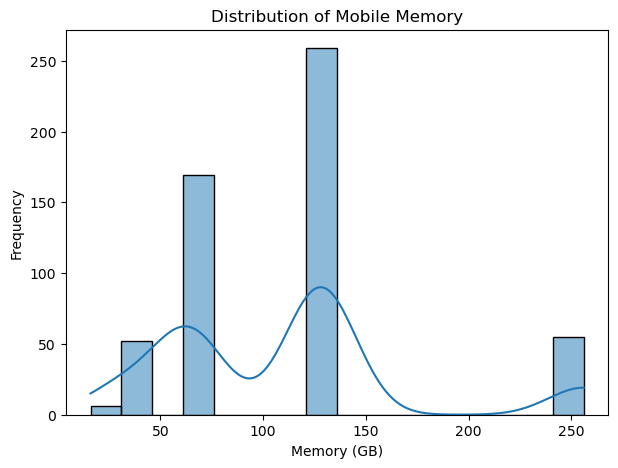

In [24]:
plt.figure(figsize=(7,5))

sns.histplot(df['Memory'], kde=True)

plt.title("Distribution of Mobile Memory")
plt.xlabel("Memory (GB)")
plt.ylabel("Frequency")

plt.show()

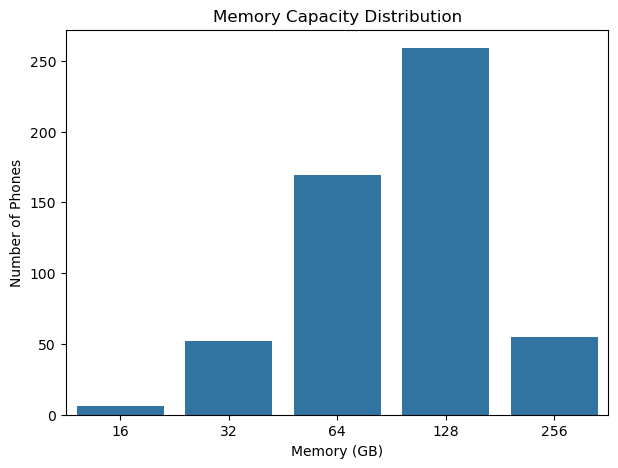

In [25]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x='Memory')

plt.title("Memory Capacity Distribution")
plt.xlabel("Memory (GB)")
plt.ylabel("Number of Phones")

plt.show()

### Interpretation : Mobile phones in the dataset are available across different storage capacities, with 128 GB and other mid-to-high storage configurations forming an important portion of the dataset. Storage capacity is potentially relevant for price prediction.

## RAM — Univariate Analysis

In [26]:
print(df['RAM'].describe())

count    541.000000
mean       5.397412
std        1.984923
min        2.000000
25%        4.000000
50%        6.000000
75%        8.000000
max        8.000000
Name: RAM, dtype: float64


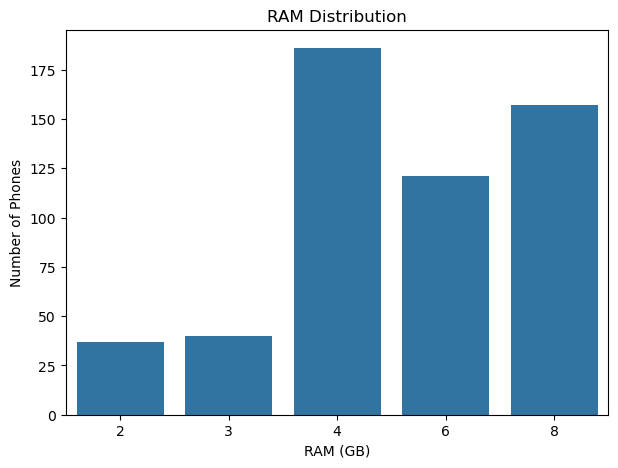

In [27]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x='RAM')

plt.title("RAM Distribution")
plt.xlabel("RAM (GB)")
plt.ylabel("Number of Phones")

plt.show()

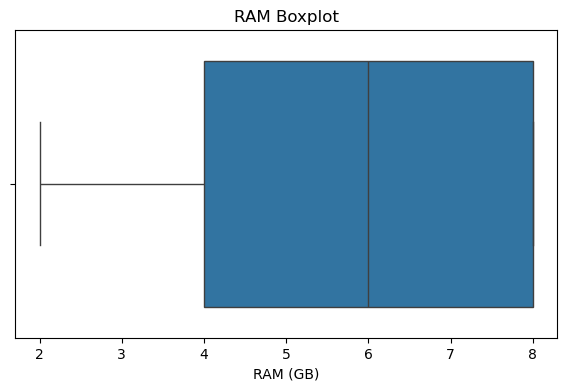

In [28]:
plt.figure(figsize=(7,4))

sns.boxplot(x=df['RAM'])

plt.title("RAM Boxplot")
plt.xlabel("RAM (GB)")

plt.show()

### Interpretation: The dataset contains phones with different RAM capacities, ranging from entry-level to higher-performance configurations. Higher RAM configurations are common in modern smartphones and may contribute to higher prices.

## Battery — Univariate Analysis

In [29]:
print(df['Battery_'].describe())

count     541.000000
mean     4871.587800
std       780.148862
min       800.000000
25%      5000.000000
50%      5000.000000
75%      5000.000000
max      7000.000000
Name: Battery_, dtype: float64


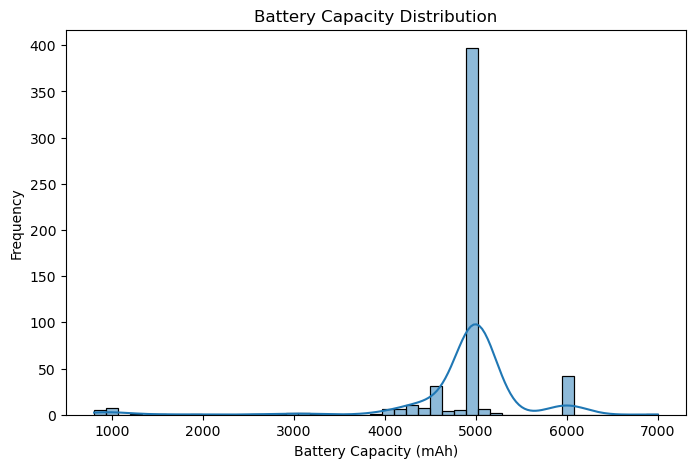

In [30]:
plt.figure(figsize=(8,5))

sns.histplot(df['Battery_'], kde=True)

plt.title("Battery Capacity Distribution")
plt.xlabel("Battery Capacity (mAh)")
plt.ylabel("Frequency")

plt.show()

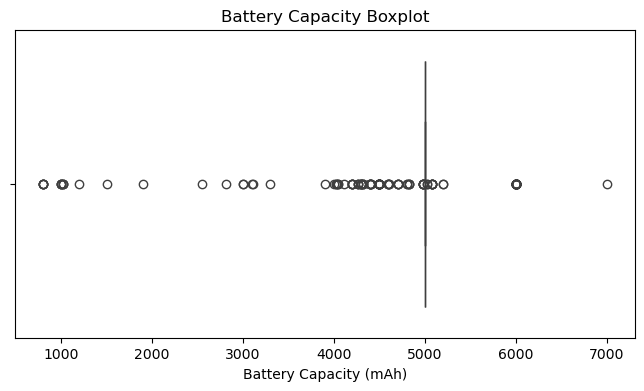

In [31]:
plt.figure(figsize=(8,4))

sns.boxplot(x=df['Battery_'])

plt.title("Battery Capacity Boxplot")
plt.xlabel("Battery Capacity (mAh)")

plt.show()

### Interpretation: Battery capacity varies considerably across smartphones. However, battery capacity alone does not necessarily indicate a premium phone, so its relationship with price should be evaluated during bivariate analysis.

## AI Lens — Univariate Analysis

In [32]:
print(df['AI Lens'].value_counts())

AI Lens
0    507
1     34
Name: count, dtype: int64


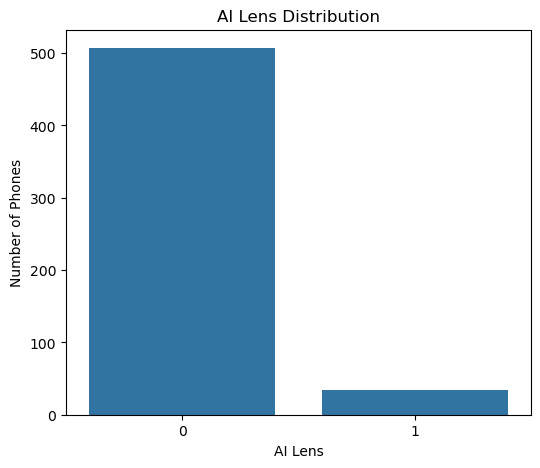

In [33]:
plt.figure(figsize=(6,5))

sns.countplot(data=df, x='AI Lens')

plt.title("AI Lens Distribution")
plt.xlabel("AI Lens")
plt.ylabel("Number of Phones")

plt.show()

In [35]:
print(
    df['AI Lens']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

AI Lens
0    93.72
1     6.28
Name: proportion, dtype: float64


### Interpretation: The AI Lens variable has two categories representing the presence or absence of the feature. The distribution indicates how common AI-lens functionality is among the phones in the dataset.

## Mobile Height — Univariate Analysis

In [36]:
print(df['Mobile Height'].describe())

count    541.000000
mean      16.431201
std        2.523553
min        4.500000
25%       16.510000
50%       16.710000
75%       16.940000
max       41.940000
Name: Mobile Height, dtype: float64


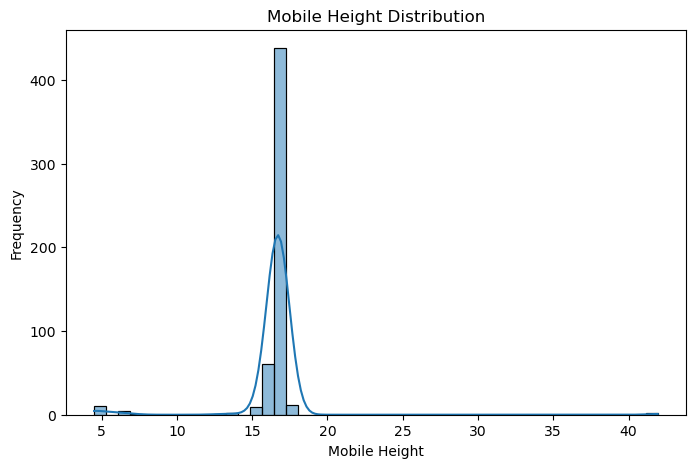

In [37]:
plt.figure(figsize=(8,5))

sns.histplot(df['Mobile Height'], kde=True)

plt.title("Mobile Height Distribution")
plt.xlabel("Mobile Height")
plt.ylabel("Frequency")

plt.show()

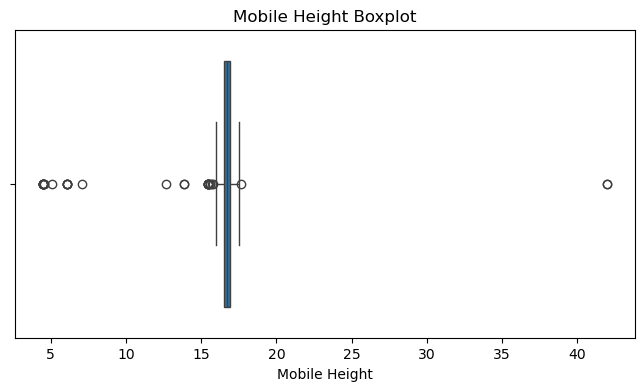

In [38]:
plt.figure(figsize=(8,4))

sns.boxplot(x=df['Mobile Height'])

plt.title("Mobile Height Boxplot")
plt.xlabel("Mobile Height")

plt.show()

In [39]:
print(
    df[df['Mobile Height'] > 20]
    [['Model', 'Mobile Height']]
)

              Model  Mobile Height
75  MOTOROLA G62 5G          41.94
88  MOTOROLA G62 5G          41.94


### Interpretation: An unusually high mobile-height value was detected. This may represent a data-entry or unit inconsistency and should be investigated before machine-learning model development.

## Prize — Target Variable

In [40]:
print(df['Prize'].describe())

count      541.000000
mean     16228.375231
std      10793.588322
min        920.000000
25%       9290.000000
50%      13499.000000
75%      19280.000000
max      80999.000000
Name: Prize, dtype: float64


In [41]:
print("Mean:", df['Prize'].mean())
print("Median:", df['Prize'].median())
print("Standard Deviation:", df['Prize'].std())
print("Minimum:", df['Prize'].min())
print("Maximum:", df['Prize'].max())
print("Skewness:", df['Prize'].skew())
print("Kurtosis:", df['Prize'].kurt())

Mean: 16228.375231053604
Median: 13499.0
Standard Deviation: 10793.58832232839
Minimum: 920
Maximum: 80999
Skewness: 2.4255791831830114
Kurtosis: 9.606035137273258


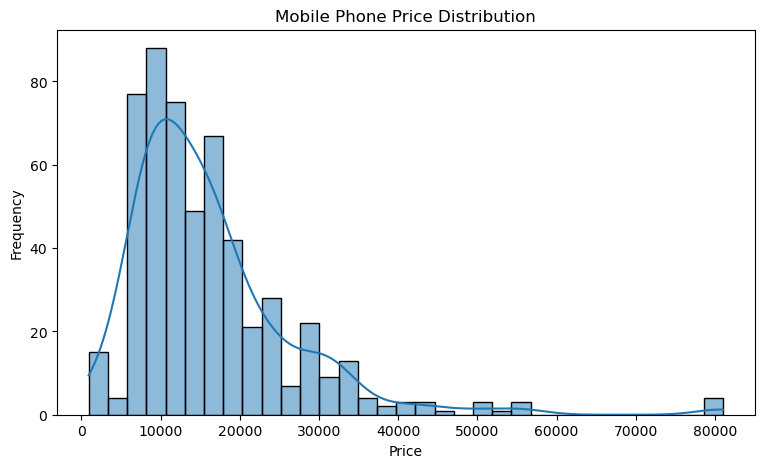

In [42]:
plt.figure(figsize=(9,5))

sns.histplot(df['Prize'], kde=True)

plt.title("Mobile Phone Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.show()

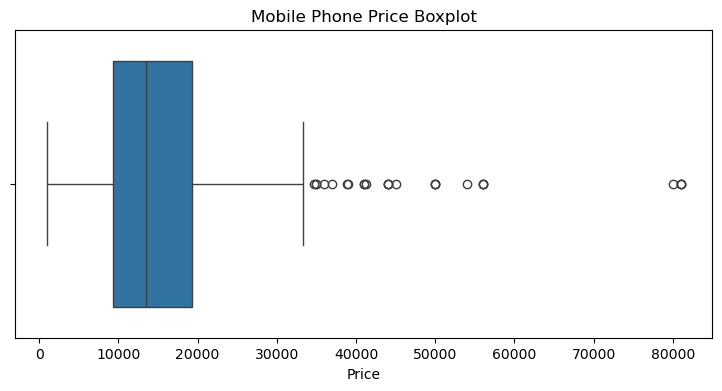

In [43]:
plt.figure(figsize=(9,4))

sns.boxplot(x=df['Prize'])

plt.title("Mobile Phone Price Boxplot")
plt.xlabel("Price")

plt.show()

### Interpretation: The mobile-phone price distribution is positively/right skewed. Most phones are concentrated in the low-to-mid price range, while a smaller number of premium smartphones have substantially higher prices.

## Price Outlier Analysis Using IQR

In [44]:
Q1 = df['Prize'].quantile(0.25)
Q3 = df['Prize'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df['Prize'] < lower) |
    (df['Prize'] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Limit:", lower)
print("Upper Limit:", upper)
print("Number of Outliers:", len(outliers))

Q1: 9290.0
Q3: 19280.0
IQR: 9990.0
Lower Limit: -5695.0
Upper Limit: 34265.0
Number of Outliers: 25


### Interpretation: The detected price outliers are likely to represent genuine premium smartphones rather than erroneous observations. Therefore, they should be retained for the prediction model unless further investigation identifies incorrect records.

## Model — Categorical Univariate Analysis

In [45]:
print("Number of unique models:",
      df['Model'].nunique())

Number of unique models: 187


In [46]:
model_count = df['Model'].value_counts().head(10)

print(model_count)

Model
vivo Y16                 9
realme C55               9
SAMSUNG Galaxy A14 5G    9
REDMI Note 12 Pro 5G     9
vivo T1 44W              8
Infinix HOT 30i          8
REDMI 10                 8
SAMSUNG Galaxy F14 5G    8
vivo T2x 5G              8
realme C33 2023          6
Name: count, dtype: int64


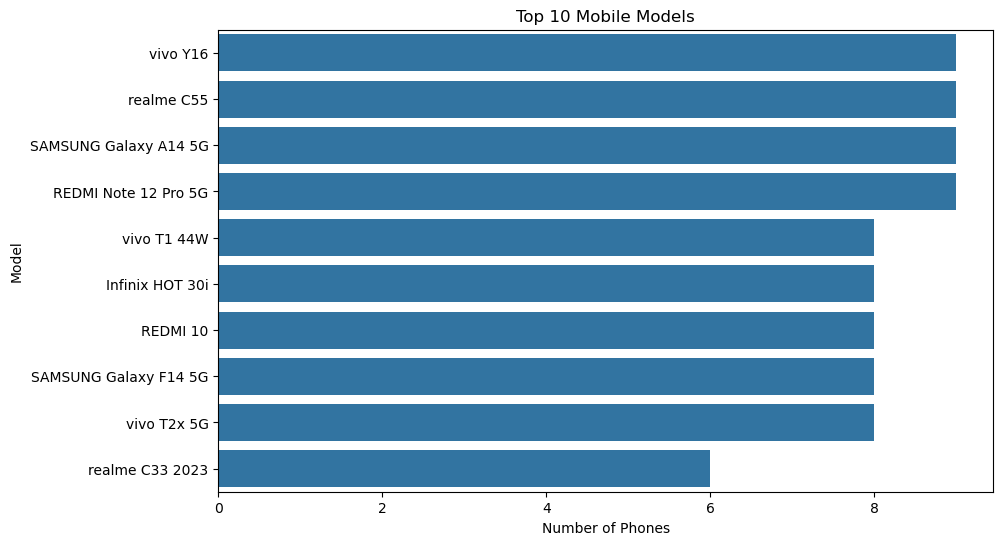

In [47]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=model_count.values,
    y=model_count.index
)

plt.title("Top 10 Mobile Models")
plt.xlabel("Number of Phones")
plt.ylabel("Model")

plt.show()

### Interpretation: The dataset contains 187 unique mobile models, indicating substantial model diversity. Because of this high cardinality, directly one-hot encoding every model may create a large number of features.

## Colour — Univariate Analysis

In [48]:
colour_count = df['Colour'].value_counts().head(10)

print(colour_count)

Colour
Yellow            12
Royal Blue         8
Power Black        8
Black              8
Midnight Black     7
Cool Blue          7
Glacier Blue       6
Aqua Blue          6
Force Black        6
Light Green        5
Name: count, dtype: int64


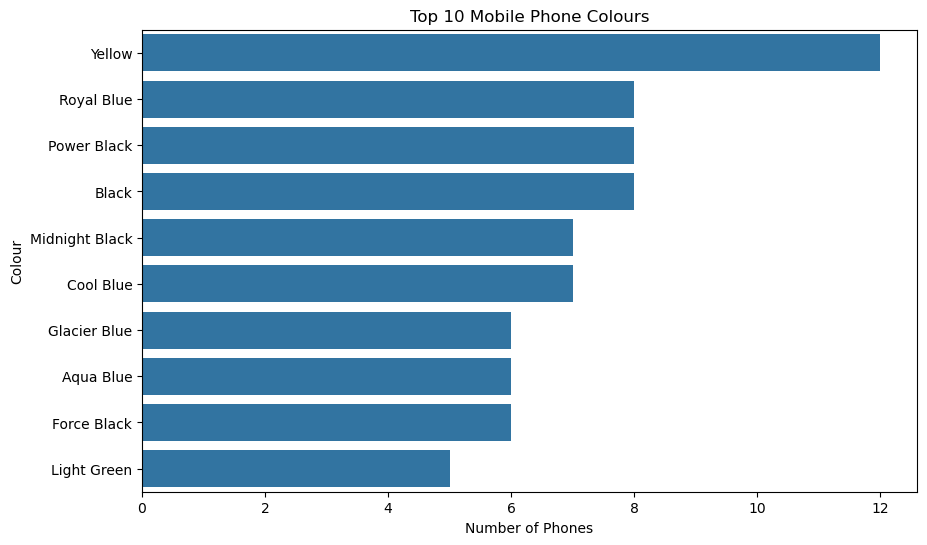

In [49]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=colour_count.values,
    y=colour_count.index
)

plt.title("Top 10 Mobile Phone Colours")
plt.xlabel("Number of Phones")
plt.ylabel("Colour")

plt.show()

### Interpretation: The colour variable has very high cardinality, with 275 unique values. A small number of colour categories occur frequently while many colours occur only once or a few times. Therefore, colour may require grouping or careful encoding during feature engineering.

## Rear Camera — Univariate Analysis

In [50]:
print(df['Rear Camera'].value_counts())

Rear Camera
50MP     260
13MP      63
64MP      62
8MP       52
48MP      31
108MP     31
0MP       10
12MP      10
200MP      8
2MP        6
5MP        3
40MP       2
32MP       2
16MP       1
Name: count, dtype: int64


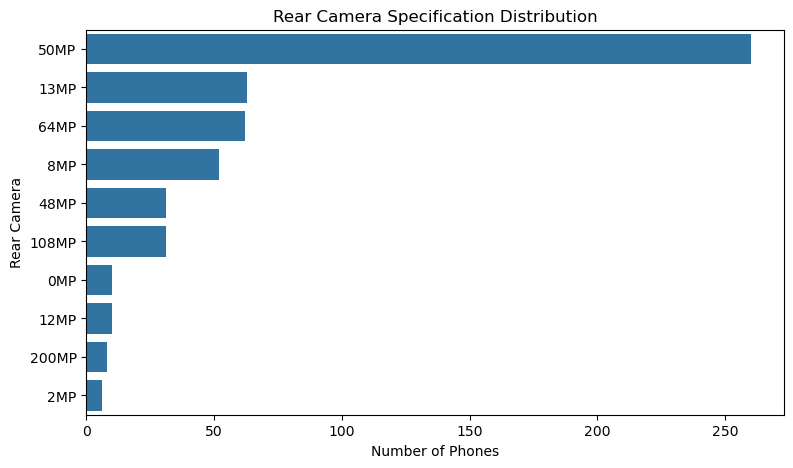

In [51]:
rear_count = df['Rear Camera'].value_counts().head(10)

plt.figure(figsize=(9,5))

sns.barplot(
    x=rear_count.values,
    y=rear_count.index
)

plt.title("Rear Camera Specification Distribution")
plt.xlabel("Number of Phones")
plt.ylabel("Rear Camera")

plt.show()

In [52]:
df['Rear_Camera_MP'] = (
    df['Rear Camera']
    .str.extract(r'(\d+\.?\d*)')[0]
    .astype(float)
)

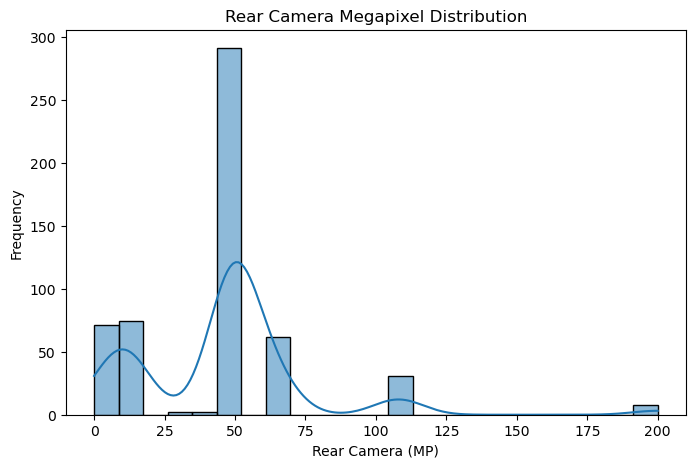

In [53]:
plt.figure(figsize=(8,5))

sns.histplot(df['Rear_Camera_MP'], kde=True)

plt.title("Rear Camera Megapixel Distribution")
plt.xlabel("Rear Camera (MP)")
plt.ylabel("Frequency")

plt.show()

### Interpretation: Rear-camera specifications vary across the phones. Converting the camera specification into megapixels creates a useful numerical feature that can later be evaluated for its effect on price.

## Front Camera — Univariate Analysis

In [54]:
print(df['Front Camera'].value_counts())

Front Camera
16MP    164
5MP     135
8MP     129
13MP     49
32MP     22
0MP      16
50MP      7
12MP      6
60MP      4
2MP       3
10MP      2
20MP      2
44MP      2
Name: count, dtype: int64


In [55]:
df['Front_Camera_MP'] = (
    df['Front Camera']
    .str.extract(r'(\d+\.?\d*)')[0]
    .astype(float)
)

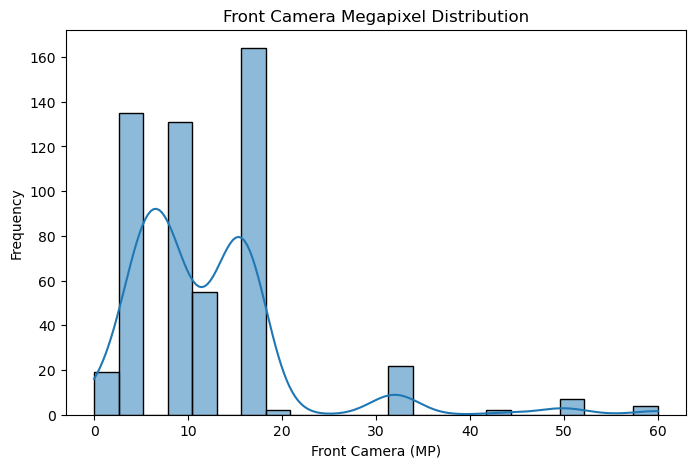

In [56]:
plt.figure(figsize=(8,5))

sns.histplot(df['Front_Camera_MP'], kde=True)

plt.title("Front Camera Megapixel Distribution")
plt.xlabel("Front Camera (MP)")
plt.ylabel("Frequency")

plt.show()

### Interpretation: Front-camera specifications show variation across mobile phones. Extracting the megapixel value converts the original text feature into a numerical variable suitable for statistical analysis and machine learning.

## Processor — Univariate Analysis

In [57]:
print("Unique processors:",
      df['Processor_'].nunique())

Unique processors: 123


In [58]:
processor_count = df['Processor_'].value_counts().head(10)

print(processor_count)

Processor_
Qualcomm Snapdragon 680       33
Unisoc T612                   21
Mediatek Helio A22            19
Mediatek Dimensity 1080       18
Qualcomm Snapdragon 695 5G    17
Mediatek Helio P35            16
Mediatek Helio G85            10
Mediatek Helio G99            10
Mediatek Dimensity 810 5G     10
Helio G88                     10
Name: count, dtype: int64


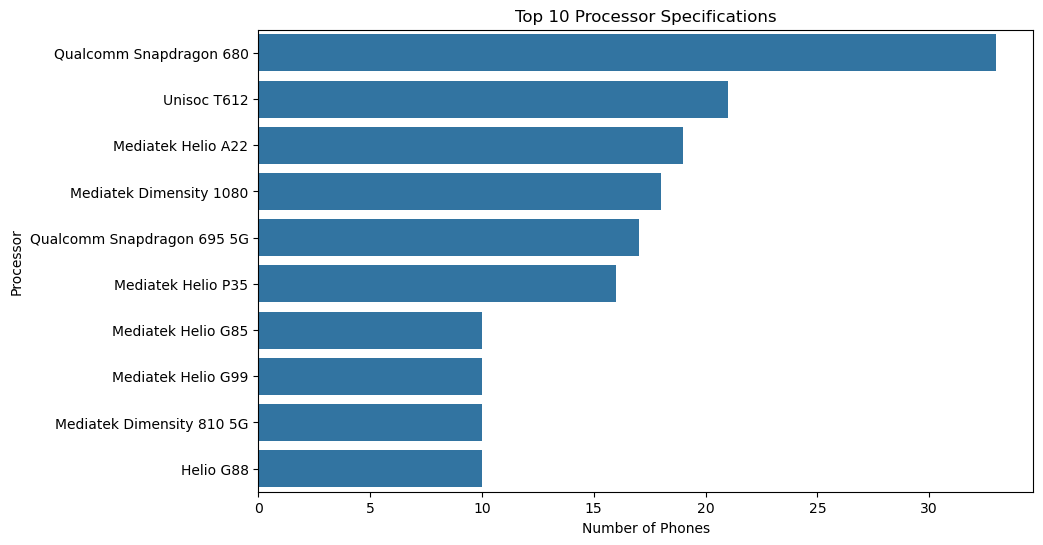

In [59]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=processor_count.values,
    y=processor_count.index
)

plt.title("Top 10 Processor Specifications")
plt.xlabel("Number of Phones")
plt.ylabel("Processor")

plt.show()

### Interpretation: The dataset contains a wide variety of processors. Processor is potentially an important feature for price prediction, but its high cardinality means that direct one-hot encoding could produce many columns.

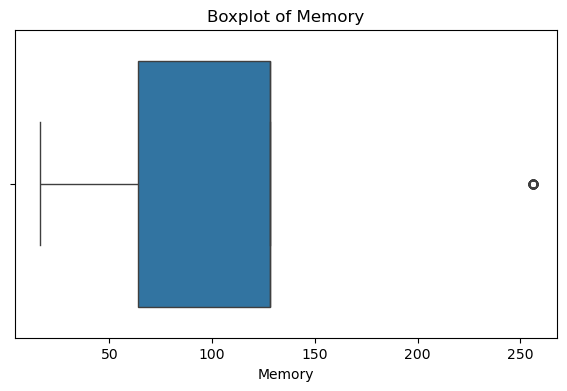

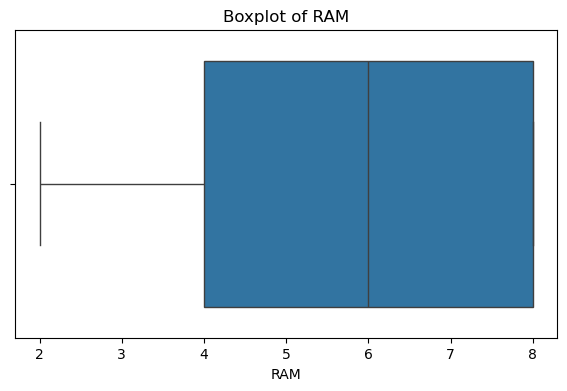

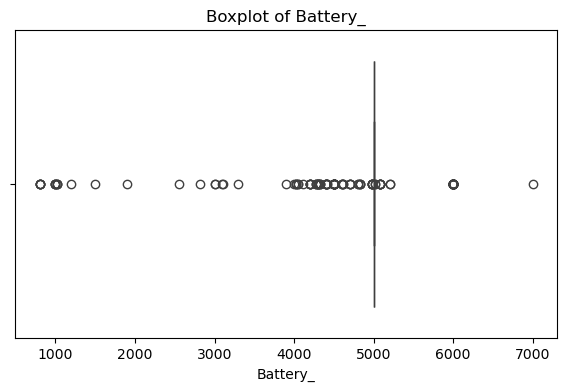

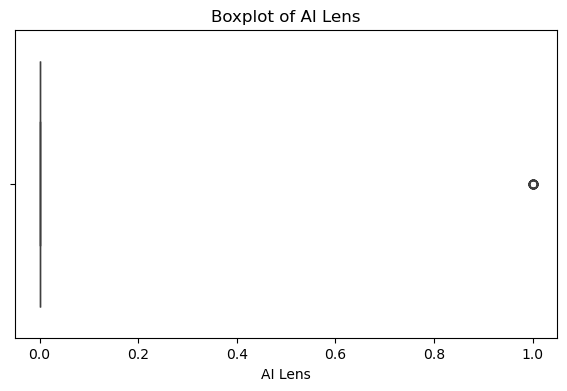

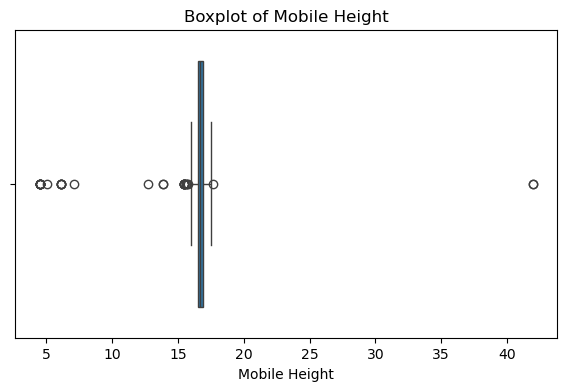

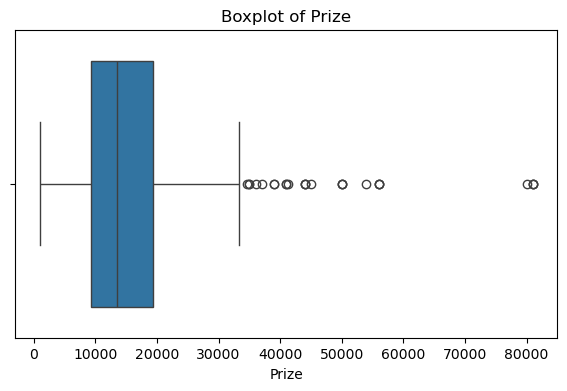

In [60]:
num_cols = [
    'Memory',
    'RAM',
    'Battery_',
    'AI Lens',
    'Mobile Height',
    'Prize'
]

for col in num_cols:

    plt.figure(figsize=(7,4))

    sns.boxplot(x=df[col])

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)

    plt.show()

# (B) Feature Extraction:

## Prepare numerical features

In [61]:
# Remove unnecessary index column
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

# Extract camera megapixels
df["Rear_Camera_MP"] = df["Rear Camera"].str.extract(r"(\d+\.?\d*)")[0].astype(float)
df["Front_Camera_MP"] = df["Front Camera"].str.extract(r"(\d+\.?\d*)")[0].astype(float)

# Convert AI Lens to numeric
df["AI_Lens"] = df["AI Lens"].map({"Yes": 1, "No": 0})

# Select numerical features
features = [
    "Memory", "RAM", "Battery_", "Mobile Height",
    "Rear_Camera_MP", "Front_Camera_MP", "AI_Lens", "Prize"
]

## Correlation analysis

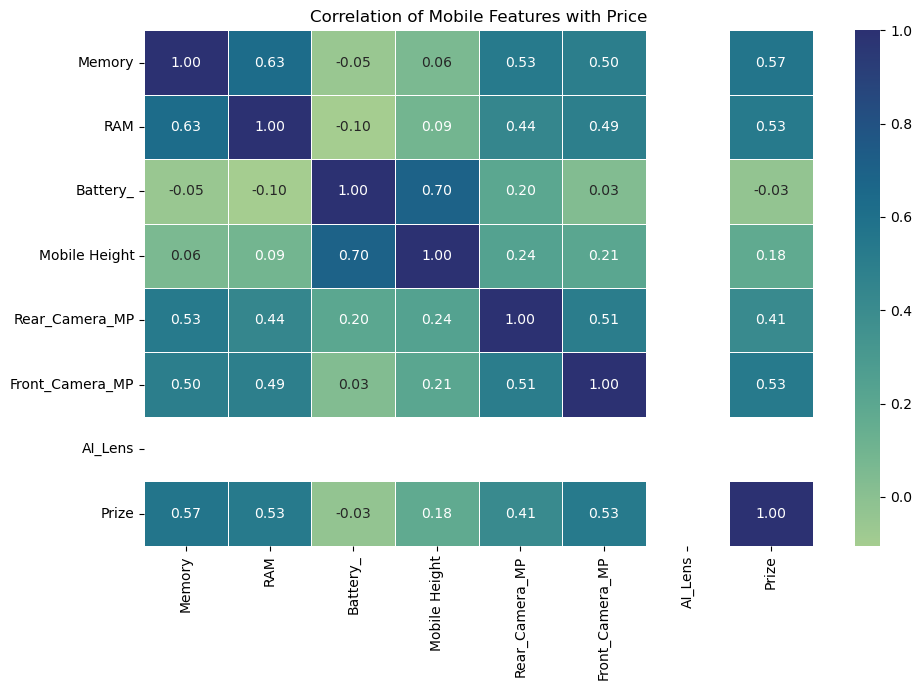

In [62]:
corr = df[features].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr,
    annot=True,
    cmap="crest",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation of Mobile Features with Price")
plt.tight_layout()
plt.show()

## Correlation with price

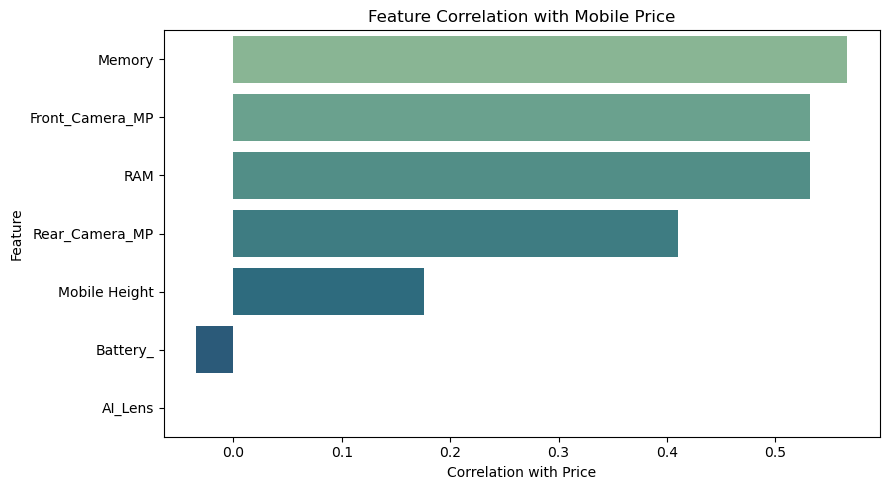

In [65]:
price_corr = corr["Prize"].drop("Prize").sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(
    x=price_corr.values,
    y=price_corr.index,
    hue=price_corr.index,
    palette="crest",
    legend=False
)

plt.title("Feature Correlation with Mobile Price")
plt.xlabel("Correlation with Price")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Memory and RAM are the strongest numerical features affecting mobile price

## Visualize the strongest features

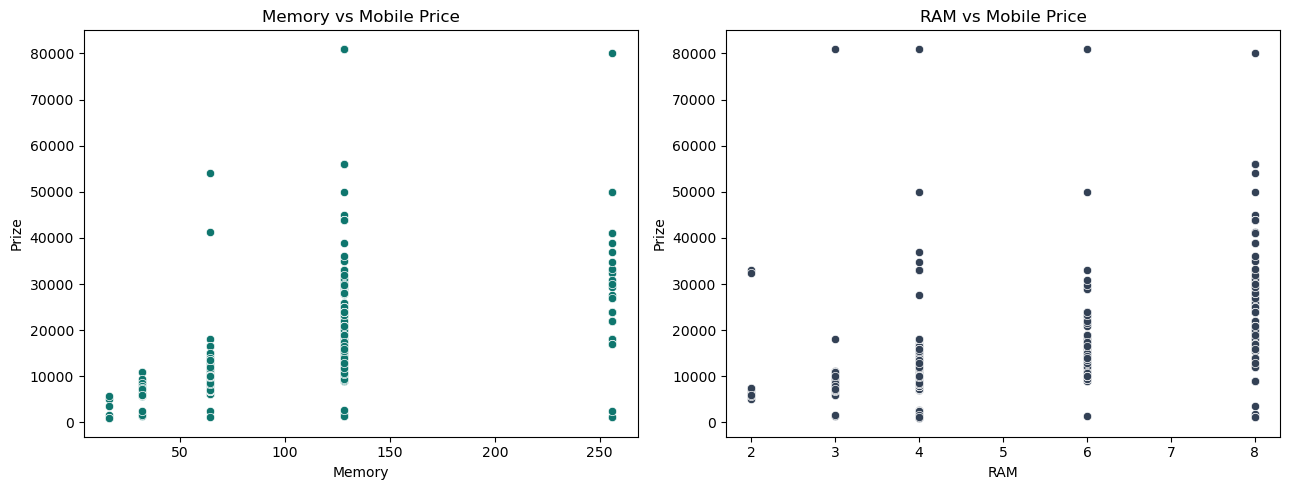

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(
    data=df,
    x="Memory",
    y="Prize",
    ax=axes[0],
    color="#0F766E"
)
axes[0].set_title("Memory vs Mobile Price")

sns.scatterplot(
    data=df,
    x="RAM",
    y="Prize",
    ax=axes[1],
    color="#334155"
)
axes[1].set_title("RAM vs Mobile Price")

plt.tight_layout()
plt.show()

## Feature importance using Random Forest

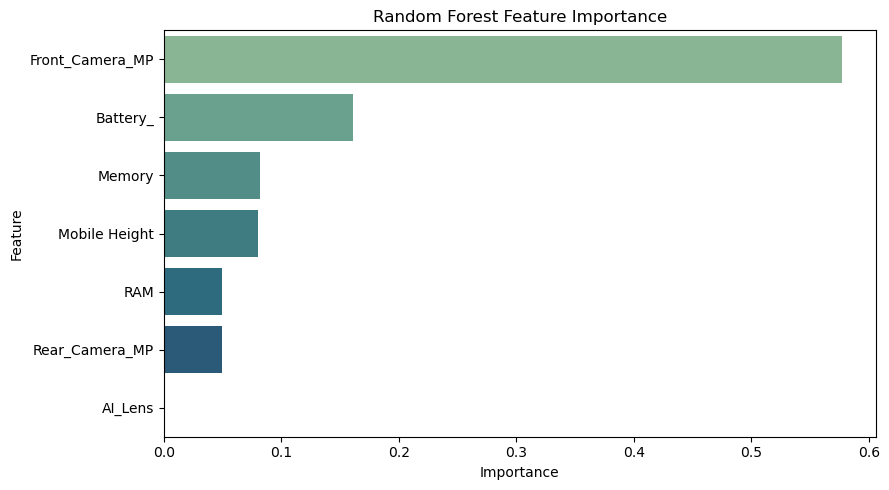

In [68]:
from sklearn.ensemble import RandomForestRegressor

X = df[[
    "Memory", "RAM", "Battery_", "Mobile Height",
    "Rear_Camera_MP", "Front_Camera_MP", "AI_Lens"
]].fillna(0)

y = df["Prize"]

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X, y)

importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(
    x=importance.values,
    y=importance.index,
    hue=price_corr.index,
    palette="crest",
    legend=False
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Feature extraction was performed using correlation analysis and Random Forest feature importance. Memory and RAM showed the strongest relationship with mobile phone price. Mobile Height and camera specifications had comparatively lower influence, while Battery Capacity showed very weak linear correlation with price. Therefore, Memory and RAM were identified as the most relevant numerical features for price prediction. Categorical features such as Model and Processor can also contribute significantly and should be encoded appropriately before model training.

# (C) Bivariate Analysis

## Memory vs Price

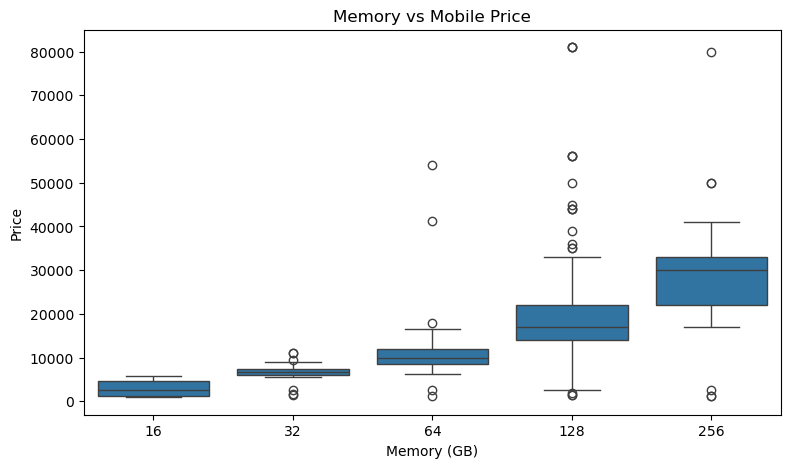

In [71]:
plt.figure(figsize=(9,5))

sns.boxplot(
    data=df,
    x="Memory",
    y="Prize"
)

plt.title("Memory vs Mobile Price")
plt.xlabel("Memory (GB)")
plt.ylabel("Price")
plt.show()

### Finding
### - Phones with higher memory/storage generally have higher prices.
### - Memory showed one of the strongest positive relationships with Prize.
### - This makes memory an important feature for price prediction.

## RAM vs Price

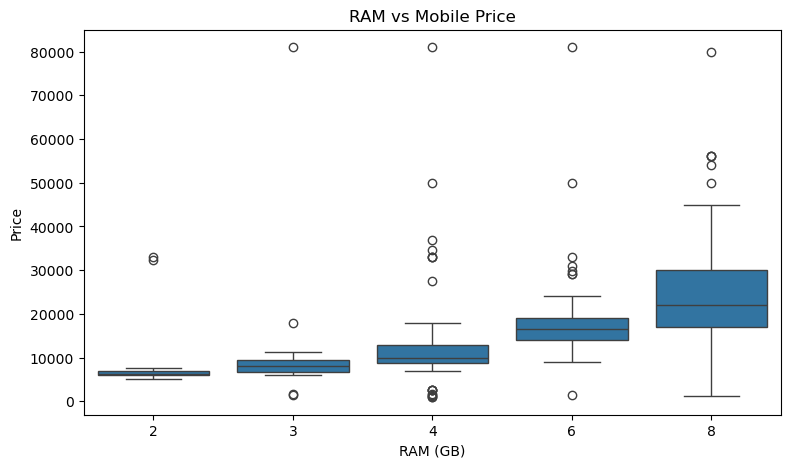

In [72]:
plt.figure(figsize=(9,5))

sns.boxplot(
    data=df,
    x="RAM",
    y="Prize"
)

plt.title("RAM vs Mobile Price")
plt.xlabel("RAM (GB)")
plt.ylabel("Price")
plt.show()

### Finding: Phones with higher RAM generally have higher prices.

## Battery vs Price — Bar Chart

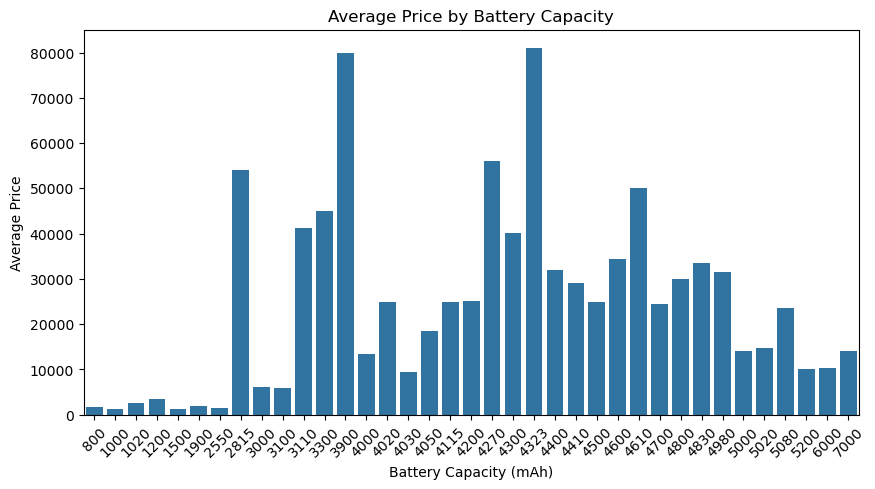

In [73]:
battery_price = df.groupby("Battery_")["Prize"].mean().reset_index()

plt.figure(figsize=(10,5))

sns.barplot(
    data=battery_price,
    x="Battery_",
    y="Prize"
)

plt.title("Average Price by Battery Capacity")
plt.xlabel("Battery Capacity (mAh)")
plt.ylabel("Average Price")
plt.xticks(rotation=45)
plt.show()

### Finding: Average price varies across battery capacities, but the relationship is relatively weak.

## Rear Camera vs Price — Bar Chart

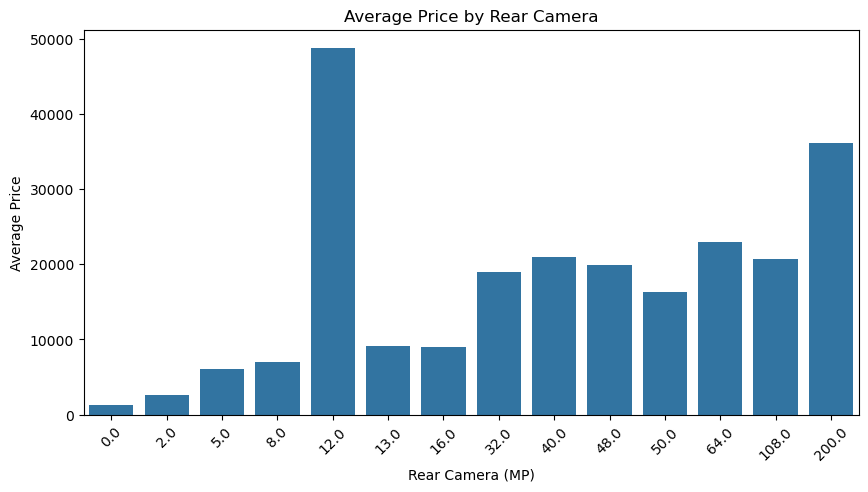

In [74]:
camera_price = df.groupby("Rear_Camera_MP")["Prize"].mean().reset_index()

plt.figure(figsize=(10,5))

sns.barplot(
    data=camera_price,
    x="Rear_Camera_MP",
    y="Prize"
)

plt.title("Average Price by Rear Camera")
plt.xlabel("Rear Camera (MP)")
plt.ylabel("Average Price")
plt.xticks(rotation=45)
plt.show()

### Finding: Higher camera specifications can be associated with higher-priced phones, but camera megapixels are not the only factor.

## Front Camera vs Price — Bar Chart

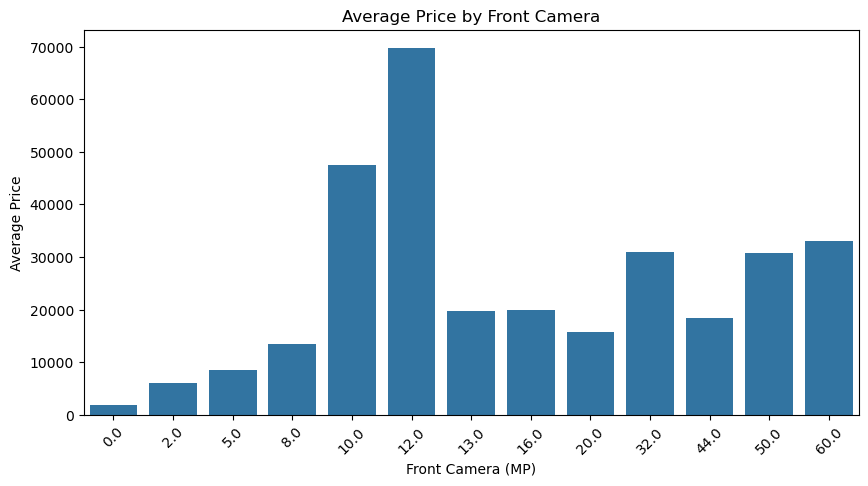

In [75]:
front_price = df.groupby("Front_Camera_MP")["Prize"].mean().reset_index()

plt.figure(figsize=(10,5))

sns.barplot(
    data=front_price,
    x="Front_Camera_MP",
    y="Prize"
)

plt.title("Average Price by Front Camera")
plt.xlabel("Front Camera (MP)")
plt.ylabel("Average Price")
plt.xticks(rotation=45)
plt.show()

### Finding
### - Front camera has a relatively weaker relationship with price.
### - Premium phones may have better front cameras, but other features contribute more strongly to price

## Correlation Heatmap

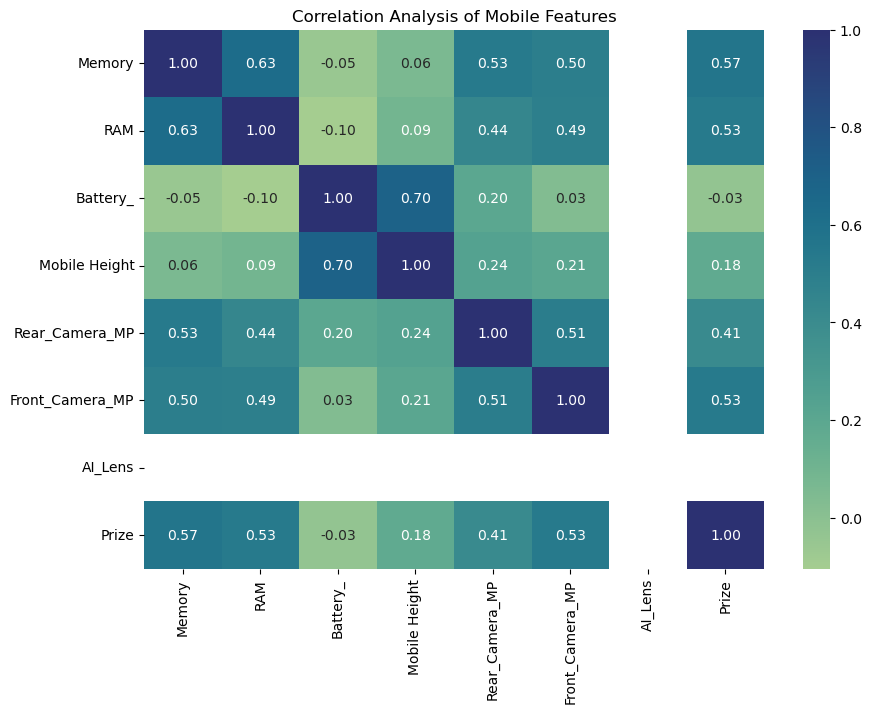

In [76]:
features = [
    "Memory",
    "RAM",
    "Battery_",
    "Mobile Height",
    "Rear_Camera_MP",
    "Front_Camera_MP",
    "AI_Lens",
    "Prize"
]

corr = df[features].corr()

plt.figure(figsize=(10,7))
sns.heatmap(
    corr,
    annot=True,
    cmap="crest",
    fmt=".2f"
)

plt.title("Correlation Analysis of Mobile Features")
plt.show()

## AI Lens vs Price

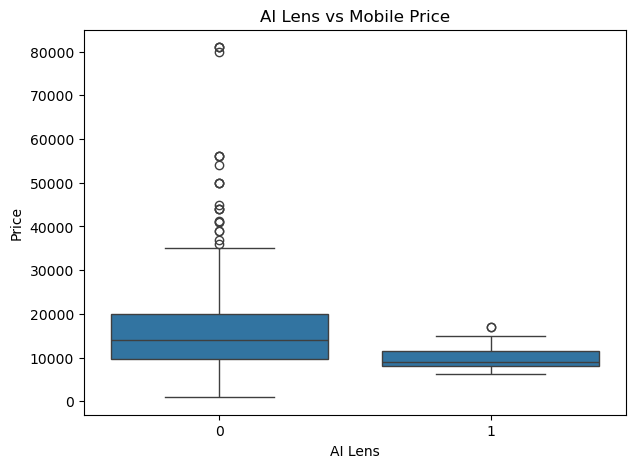

In [77]:
plt.figure(figsize=(7,5))

sns.boxplot(
    data=df,
    x="AI Lens",
    y="Prize"
)

plt.title("AI Lens vs Mobile Price")
plt.xlabel("AI Lens")
plt.ylabel("Price")
plt.show()

### Finding
### - Phones with and without AI Lens have different price distributions.
### - However, AI Lens has a much weaker relationship with price than Memory and RAM.
### - AI Lens should therefore be considered a supporting feature rather than a primary price driver.

## Processor vs Price

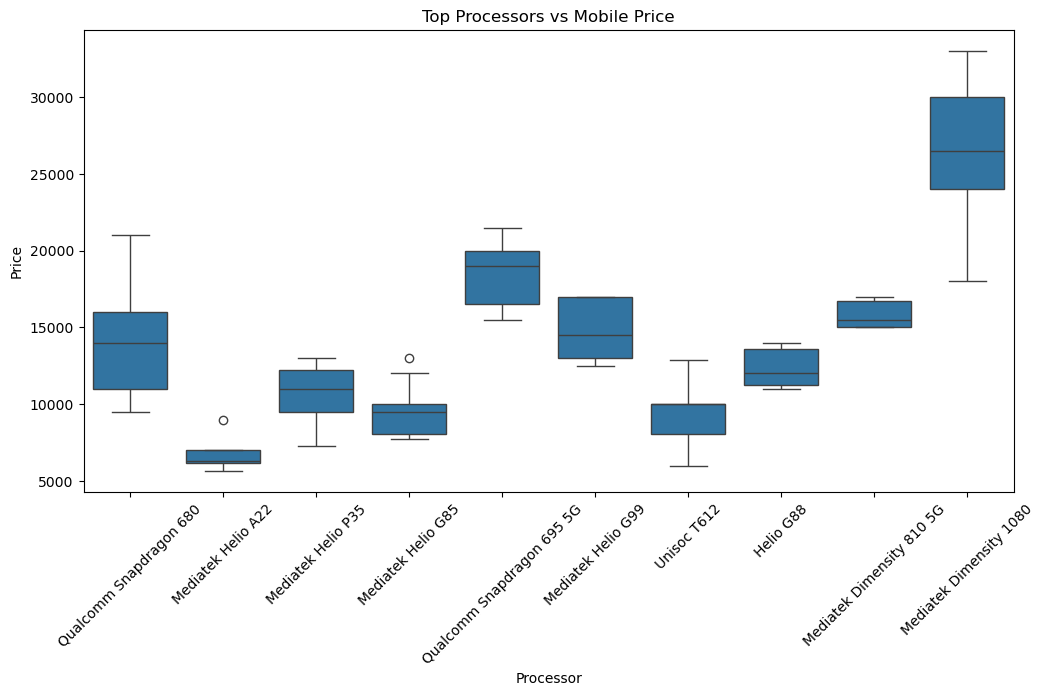

In [78]:
top_processors = df["Processor_"].value_counts().head(10).index

processor_df = df[df["Processor_"].isin(top_processors)]

plt.figure(figsize=(12,6))

sns.boxplot(
    data=processor_df,
    x="Processor_",
    y="Prize"
)

plt.xticks(rotation=45)
plt.title("Top Processors vs Mobile Price")
plt.xlabel("Processor")
plt.ylabel("Price")
plt.show()

### Finding
- Different processors show different price distributions.
- Premium processors are generally associated with higher-priced phones.
- Processor is likely an important categorical feature for the prediction model.

## Colour vs Price

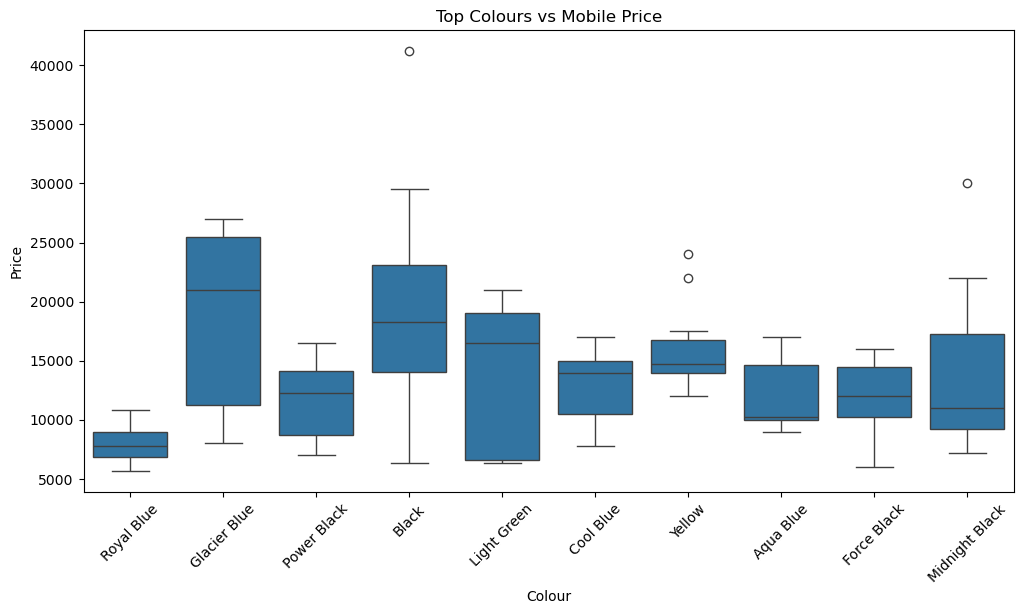

In [79]:
top_colours = df["Colour"].value_counts().head(10).index

colour_df = df[df["Colour"].isin(top_colours)]

plt.figure(figsize=(12,6))

sns.boxplot(
    data=colour_df,
    x="Colour",
    y="Prize"
)

plt.xticks(rotation=45)
plt.title("Top Colours vs Mobile Price")
plt.xlabel("Colour")
plt.ylabel("Price")
plt.show()

### Finding
- Colour does not appear to be a major direct price determinant.
- Differences in price are more likely related to technical specifications and brand/model.

## Model vs Price

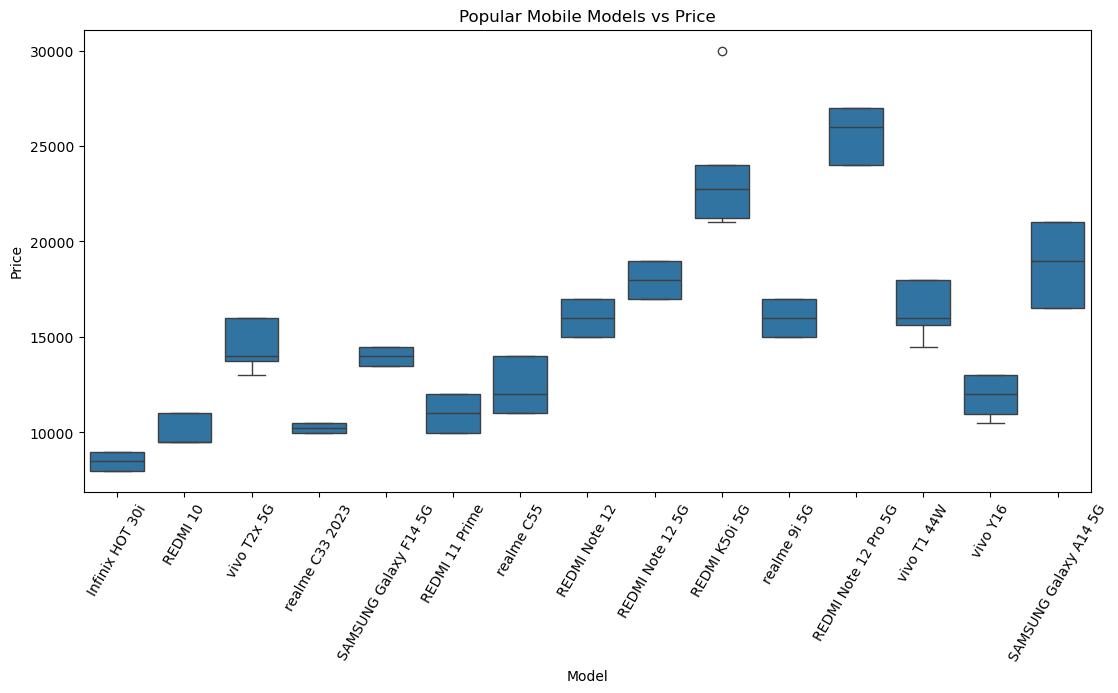

In [80]:
top_models = df["Model"].value_counts().head(15).index

model_df = df[df["Model"].isin(top_models)]

plt.figure(figsize=(13,6))

sns.boxplot(
    data=model_df,
    x="Model",
    y="Prize"
)

plt.xticks(rotation=60)
plt.title("Popular Mobile Models vs Price")
plt.xlabel("Model")
plt.ylabel("Price")
plt.show()

### Finding
- Different models have substantially different price ranges.
- Model captures the combined effect of brand, processor, camera, memory, and other specifications.
- Therefore, Model can be an important predictive feature.

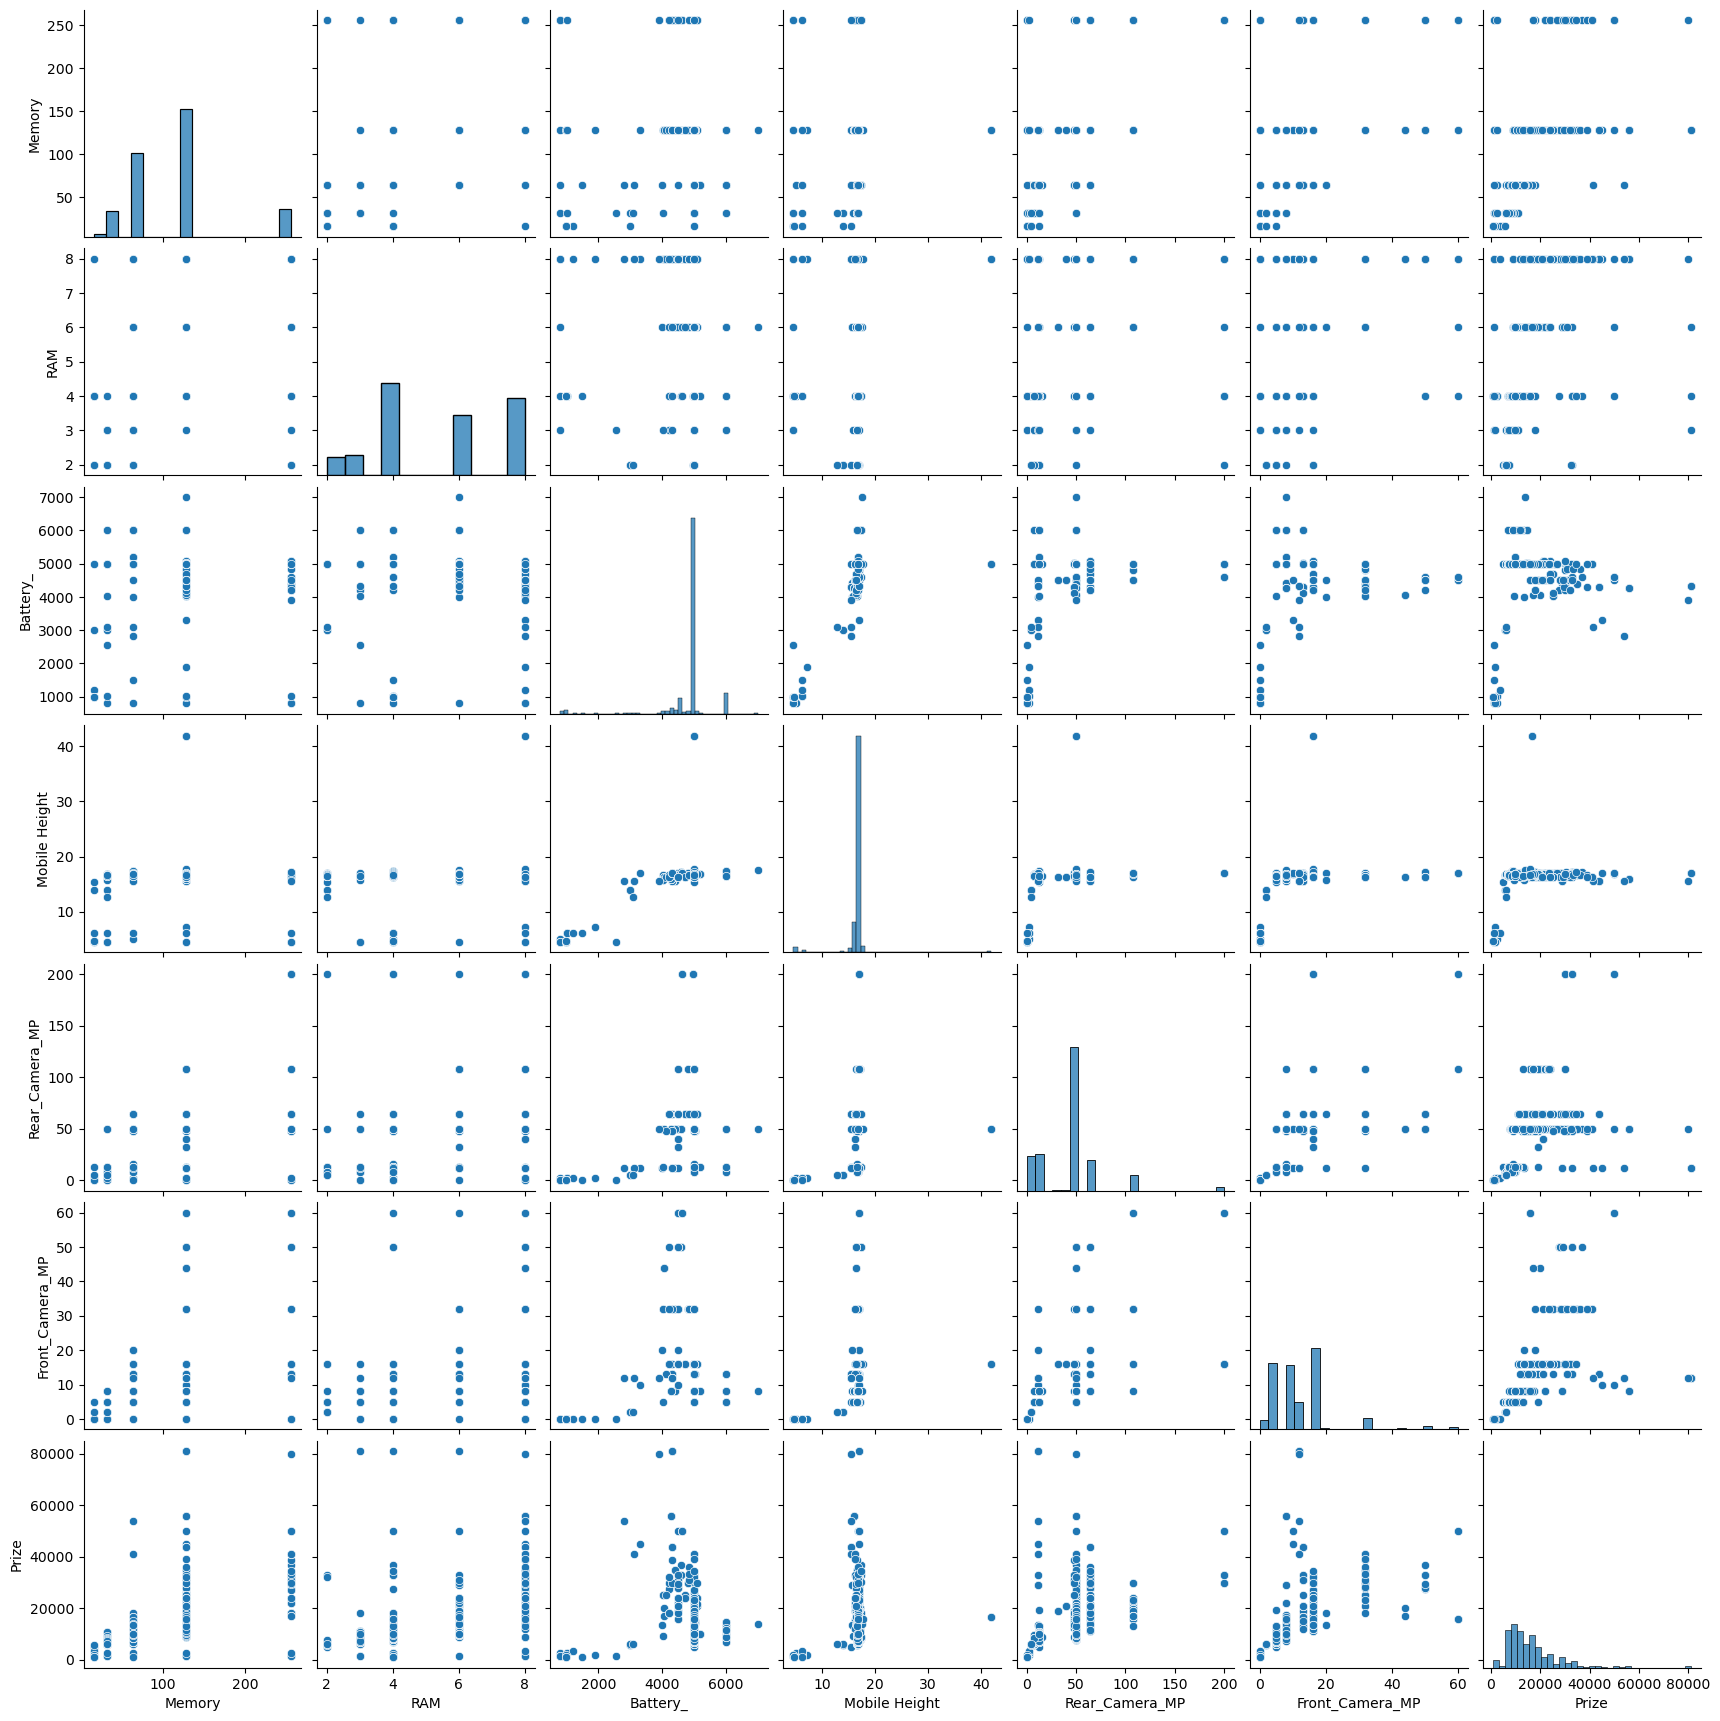

In [81]:
features = [
    "Memory",
    "RAM",
    "Battery_",
    "Mobile Height",
    "Rear_Camera_MP",
    "Front_Camera_MP",
    "Prize"
]

sns.pairplot(df[features])
plt.show()

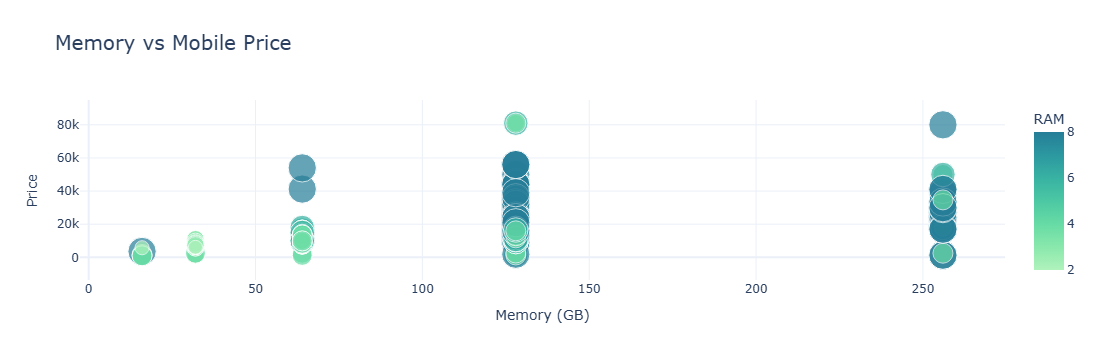

In [83]:
import plotly.express as px

fig = px.scatter(
    df,
    x="Memory",
    y="Prize",
    size="RAM",
    hover_data=["Model", "Processor_", "Battery_"],
    title="Memory vs Mobile Price",
    color="RAM",
    color_continuous_scale="Tealgrn"
)

fig.update_layout(
    template="plotly_white",
    xaxis_title="Memory (GB)",
    yaxis_title="Price",
    title_font=dict(size=20)
)

fig.show()

### Memory and RAM are the strongest numerical features associated with mobile phone price, while processor and model provide additional categorical information. Battery capacity and colour show comparatively weaker relationships with price.

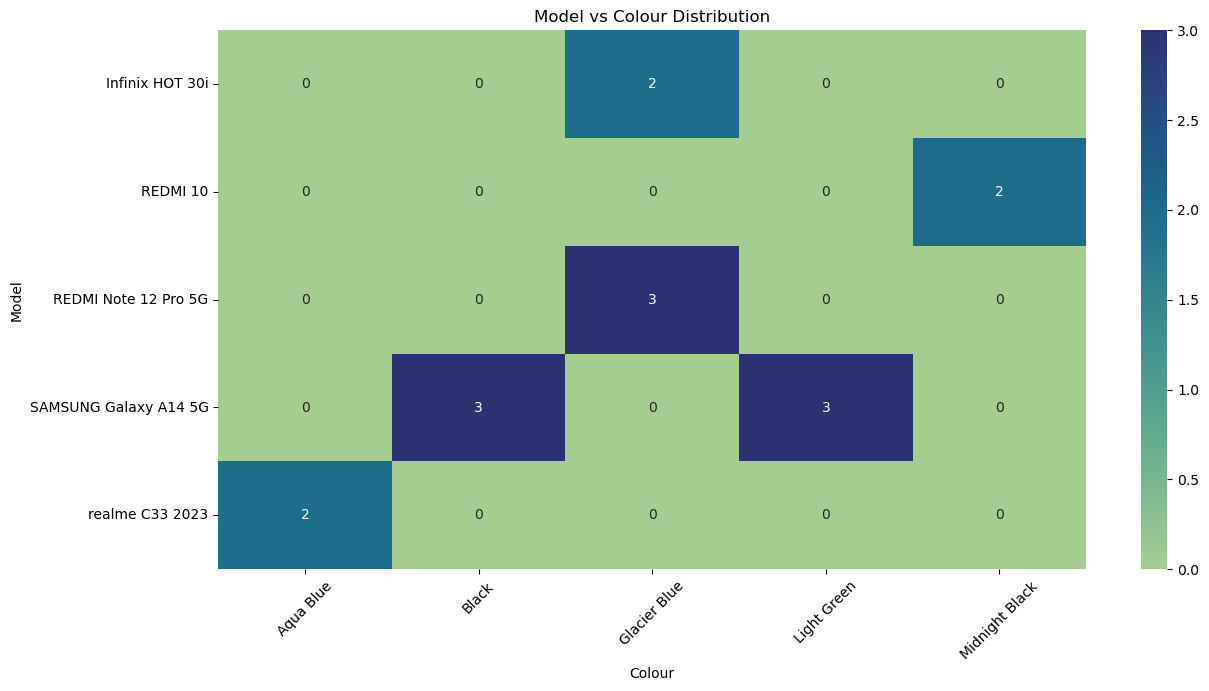

In [85]:
# Top 10 models
top_models = df["Model"].value_counts().head(10).index

# Top 10 colours
top_colours = df["Colour"].value_counts().head(10).index

# Filter data
temp = df[
    df["Model"].isin(top_models) &
    df["Colour"].isin(top_colours)
]

# Cross-tabulation
model_colour = pd.crosstab(
    temp["Model"],
    temp["Colour"]
)

# Heatmap
plt.figure(figsize=(14,7))

sns.heatmap(
    model_colour,
    annot=True,
    fmt="d",
    cmap="crest"
)

plt.title("Model vs Colour Distribution")
plt.xlabel("Colour")
plt.ylabel("Model")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

### Interpretation
- Each cell shows the number of phones available for a particular Model–Colour combination.
- Darker cells indicate more phones with that combination.
- This helps identify which colours are most commonly associated with particular models.
- It also shows whether certain models are available in only a few colours or many colours.

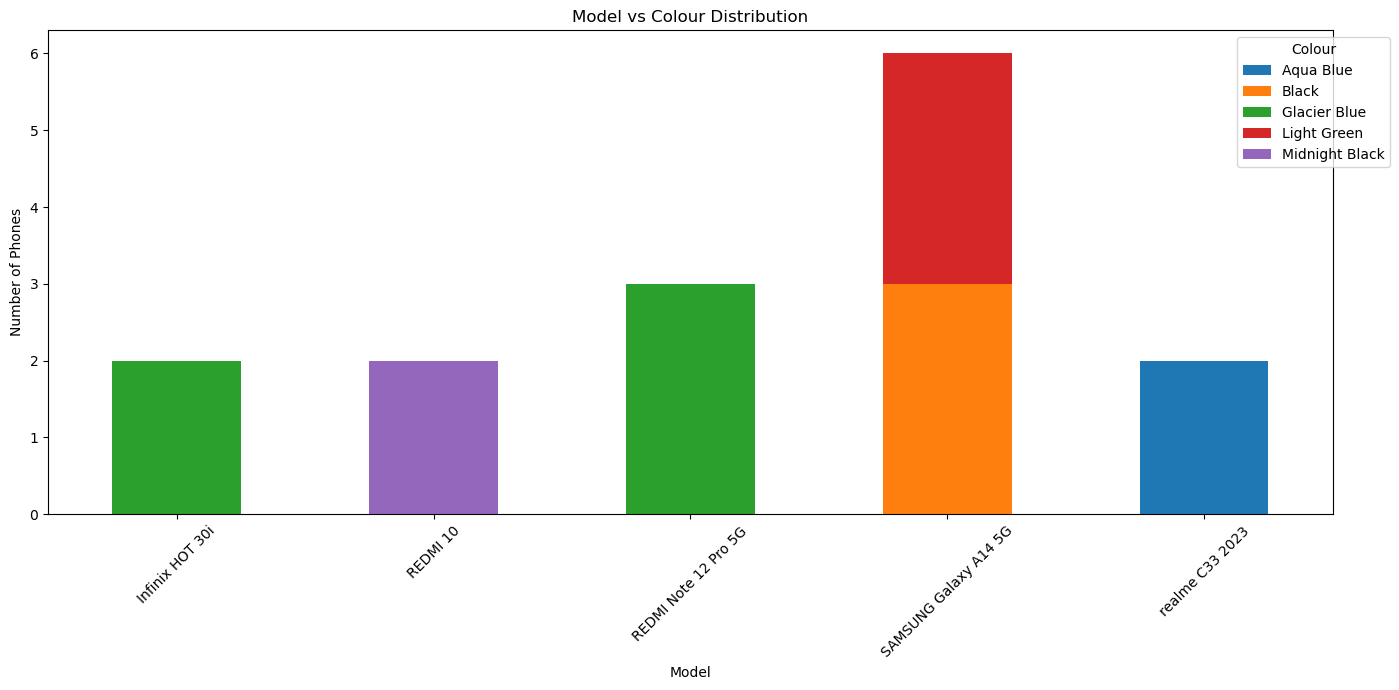

In [87]:
model_colour.plot(
    kind="bar",
    stacked=True,
    figsize=(14,7)
)

plt.title("Model vs Colour Distribution")
plt.xlabel("Model")
plt.ylabel("Number of Phones")
plt.xticks(rotation=45)
plt.legend(title="Colour", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

## Model vs AI Lens


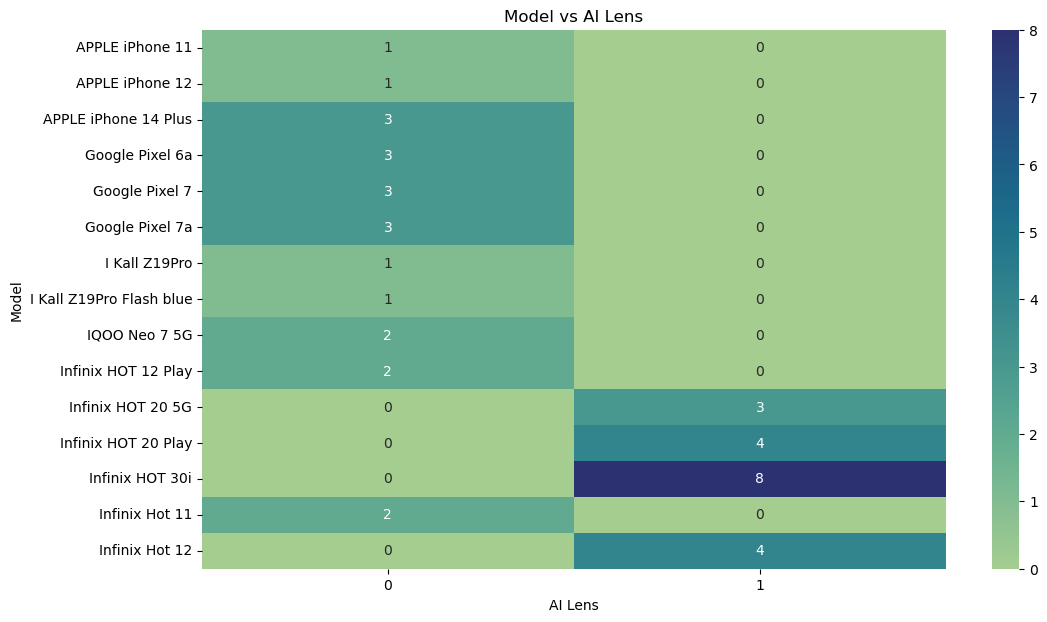

In [89]:
table = pd.crosstab(df["Model"], df["AI Lens"])

plt.figure(figsize=(12,7))
sns.heatmap(table.head(15), annot=True, fmt="d", cmap="crest")
plt.title("Model vs AI Lens")
plt.show()

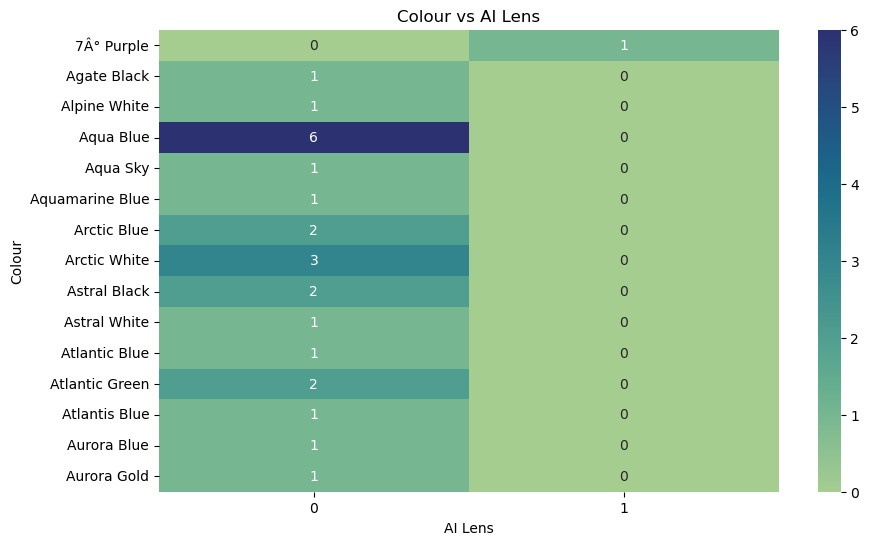

In [90]:
table = pd.crosstab(df["Colour"], df["AI Lens"])

plt.figure(figsize=(10,6))
sns.heatmap(table.head(15), annot=True, fmt="d", cmap="crest")
plt.title("Colour vs AI Lens")
plt.show()

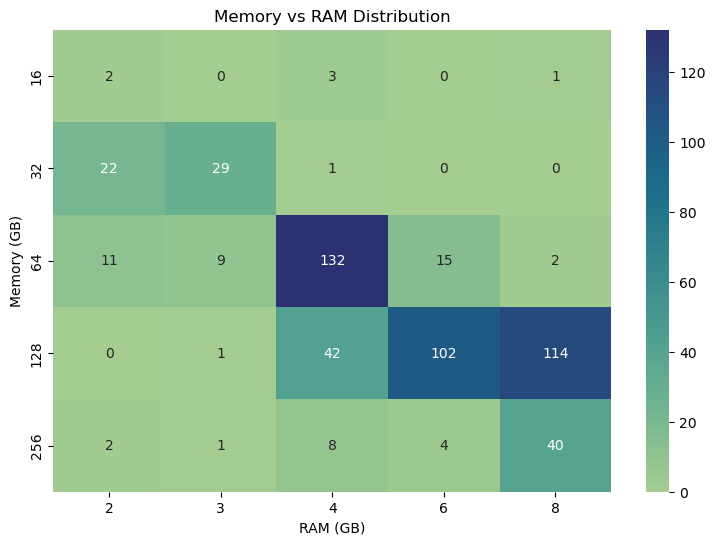

In [91]:
table = pd.crosstab(df["Memory"], df["RAM"])

plt.figure(figsize=(9,6))
sns.heatmap(table, annot=True, fmt="d", cmap="crest")

plt.title("Memory vs RAM Distribution")
plt.xlabel("RAM (GB)")
plt.ylabel("Memory (GB)")
plt.show()

## Finding: This can reveal common combinations such as 128 GB + 6 GB RAM, 256 GB + 8 GB RAM, etc., which is useful for understanding phone configurations.

# (D)Multivariate Analysis

## Memory + RAM + Price

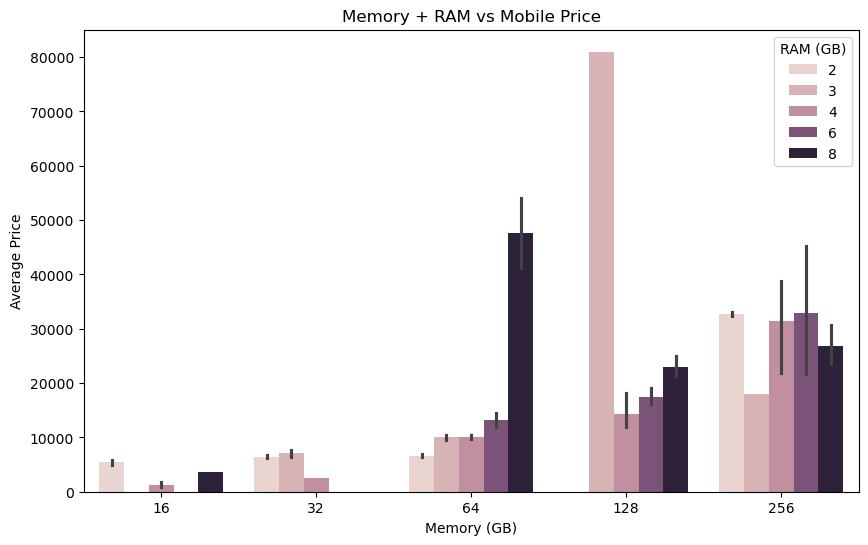

In [92]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=df,
    x="Memory",
    y="Prize",
    hue="RAM"
)

plt.title("Memory + RAM vs Mobile Price")
plt.xlabel("Memory (GB)")
plt.ylabel("Average Price")
plt.legend(title="RAM (GB)")
plt.show()

### Finding
- Price generally increases with higher Memory and RAM.
- High-memory phones with higher RAM tend to belong to premium price ranges.
- This confirms that Memory and RAM together are important price-related features.

### Memory + RAM + Processor + Price

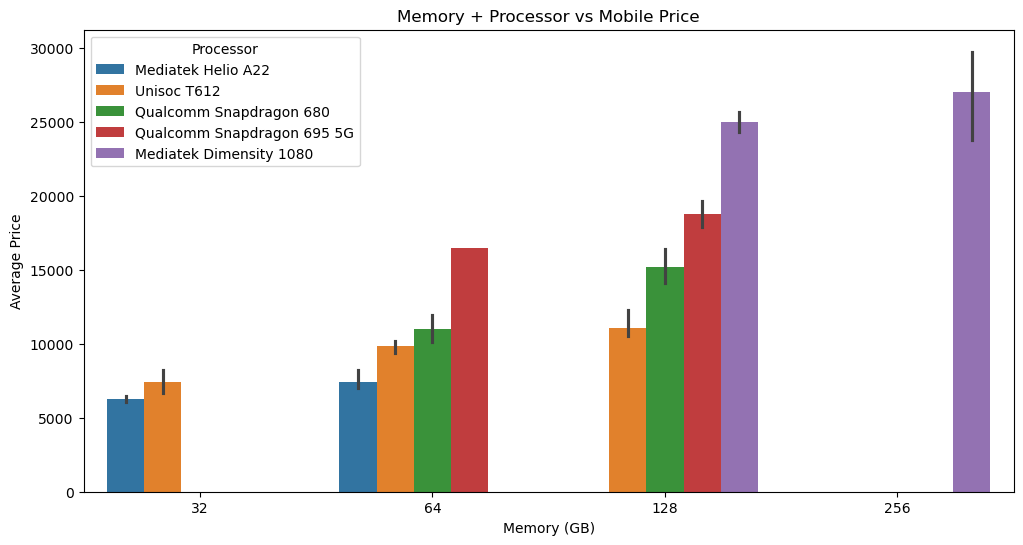

In [93]:
top_processors = df["Processor_"].value_counts().head(5).index

temp = df[df["Processor_"].isin(top_processors)]

plt.figure(figsize=(12,6))

sns.barplot(
    data=temp,
    x="Memory",
    y="Prize",
    hue="Processor_"
)

plt.title("Memory + Processor vs Mobile Price")
plt.xlabel("Memory (GB)")
plt.ylabel("Average Price")
plt.legend(title="Processor")
plt.show()

### Finding
- Phones with similar memory can have different prices depending on the processor.
- Processor therefore provides additional information beyond storage.
- Premium processors generally appear in higher-priced configurations.

### RAM + Memory + AI Lens + Price

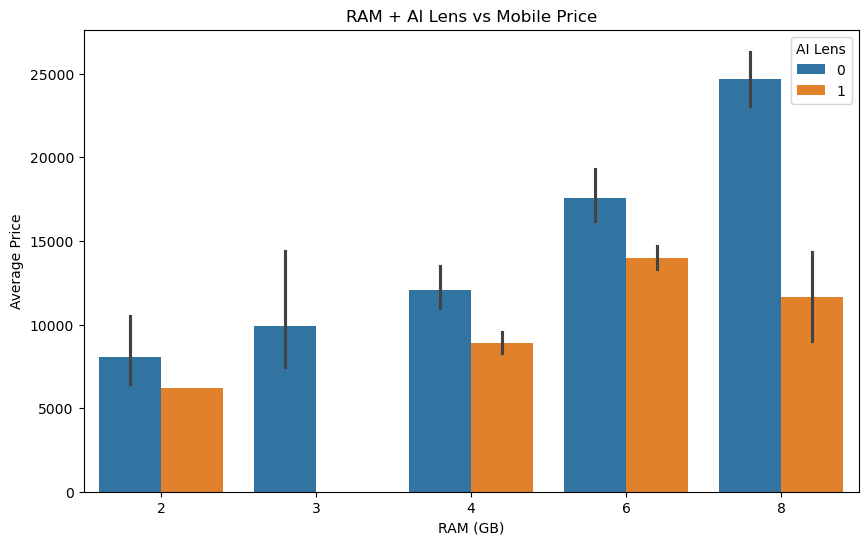

In [94]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=df,
    x="RAM",
    y="Prize",
    hue="AI Lens"
)

plt.title("RAM + AI Lens vs Mobile Price")
plt.xlabel("RAM (GB)")
plt.ylabel("Average Price")
plt.legend(title="AI Lens")
plt.show()

### Finding
Phones with higher RAM generally have higher prices, while AI Lens provides an additional but weaker distinction between price groups.

## Memory + RAM + Camera + Price

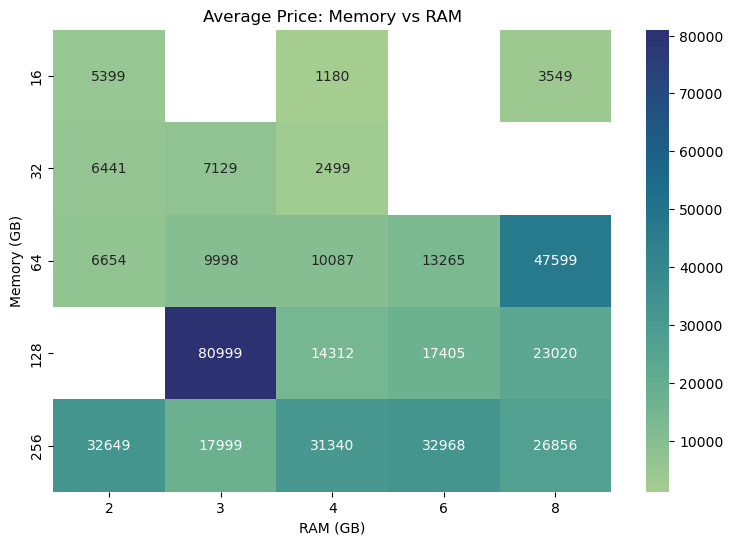

In [95]:
pivot = df.pivot_table(
    values="Prize",
    index="Memory",
    columns="RAM",
    aggfunc="mean"
)

plt.figure(figsize=(9,6))

sns.heatmap(
    pivot,
    annot=True,
    fmt=".0f",
    cmap="crest"
)

plt.title("Average Price: Memory vs RAM")
plt.xlabel("RAM (GB)")
plt.ylabel("Memory (GB)")
plt.show()

### Finding
- The heatmap clearly shows how Memory and RAM combinations affect average price.
- Higher Memory–RAM combinations generally correspond to higher prices.
- This is a strong visualization for your presentation.

## Battery + RAM + Price

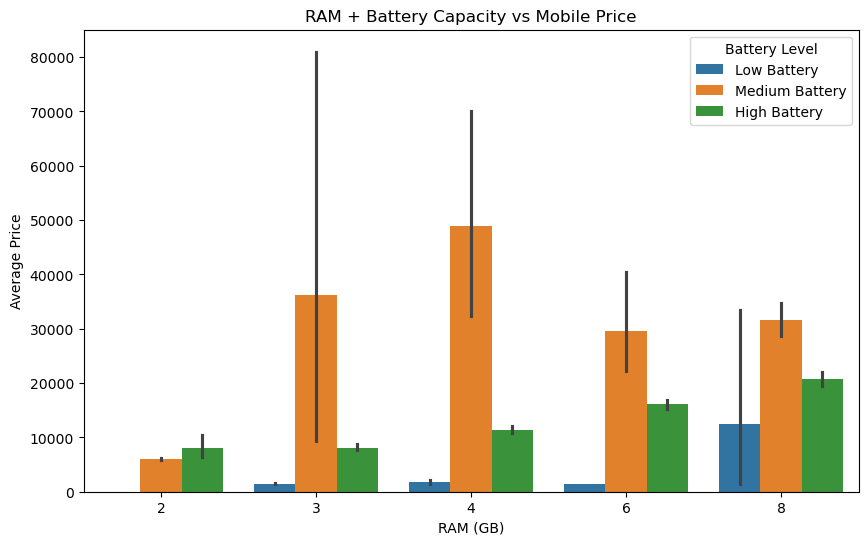

In [96]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=df,
    x="RAM",
    y="Prize",
    hue=pd.cut(
        df["Battery_"],
        bins=3,
        labels=["Low Battery", "Medium Battery", "High Battery"]
    )
)

plt.title("RAM + Battery Capacity vs Mobile Price")
plt.xlabel("RAM (GB)")
plt.ylabel("Average Price")
plt.legend(title="Battery Level")
plt.show()

### Finding
- RAM has a stronger relationship with price than battery capacity.
- Battery capacity provides additional information but is not a dominant price factor.

## Camera + RAM + Price

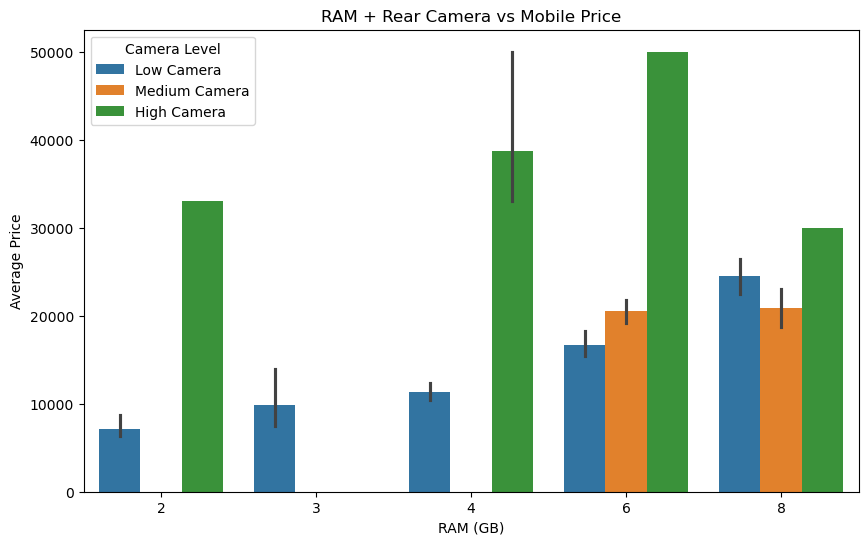

In [97]:
df["Camera_Level"] = pd.cut(
    df["Rear_Camera_MP"],
    bins=3,
    labels=["Low Camera", "Medium Camera", "High Camera"]
)

plt.figure(figsize=(10,6))

sns.barplot(
    data=df,
    x="RAM",
    y="Prize",
    hue="Camera_Level"
)

plt.title("RAM + Rear Camera vs Mobile Price")
plt.xlabel("RAM (GB)")
plt.ylabel("Average Price")
plt.legend(title="Camera Level")
plt.show()

### Finding
Phones combining higher RAM and better rear-camera specifications tend to occupy higher price ranges.

## Model + Memory + RAM + Price

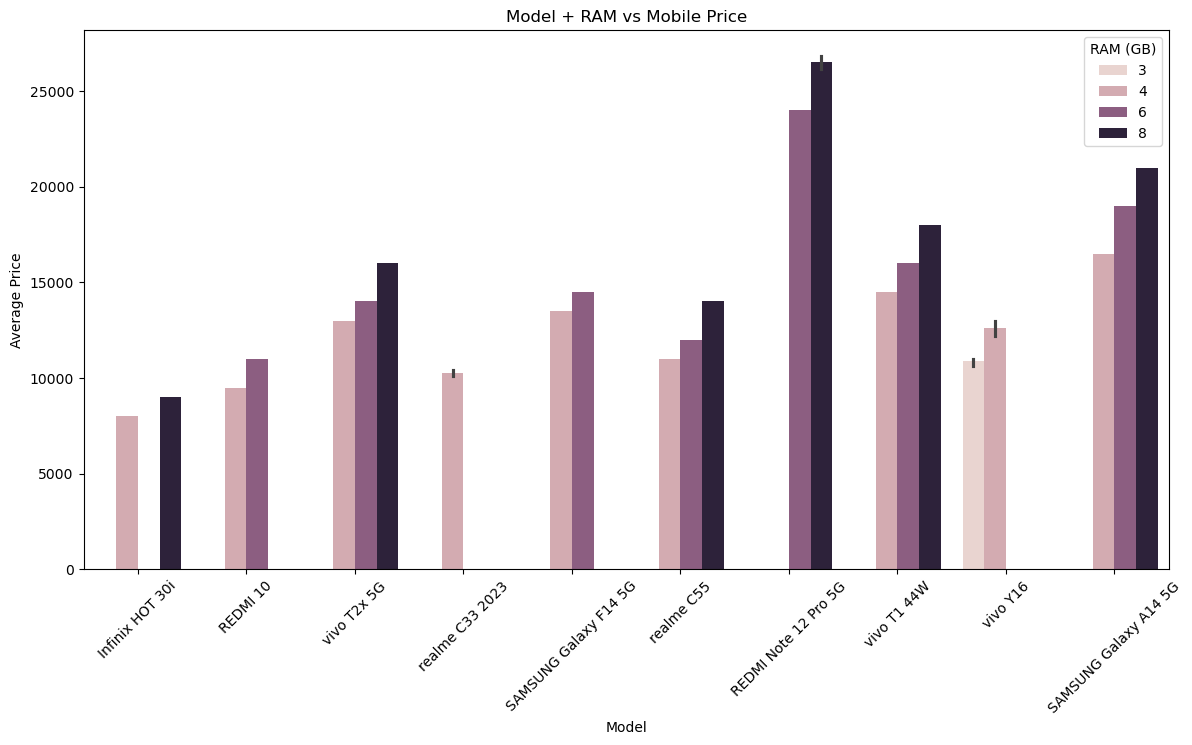

In [98]:
top_models = df["Model"].value_counts().head(10).index

temp = df[df["Model"].isin(top_models)]

plt.figure(figsize=(14,7))

sns.barplot(
    data=temp,
    x="Model",
    y="Prize",
    hue="RAM"
)

plt.title("Model + RAM vs Mobile Price")
plt.xlabel("Model")
plt.ylabel("Average Price")
plt.xticks(rotation=45)
plt.legend(title="RAM (GB)")
plt.show()

### Finding
- Different models have different price ranges even when RAM is similar.
- This indicates that model/brand-related information captures additional pricing factors.
- RAM alone cannot completely explain the price

## Processor + RAM + Memory + Price

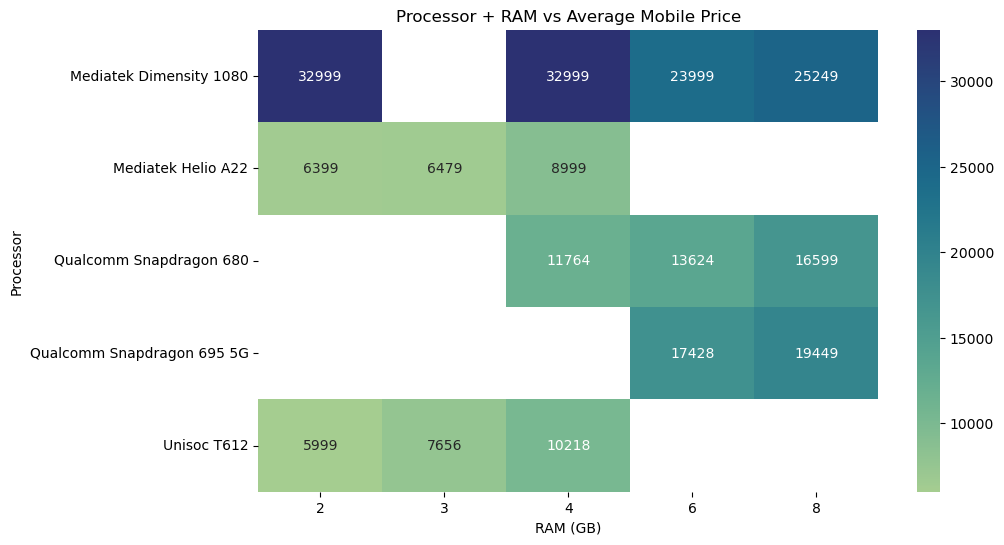

In [99]:
top_processors = df["Processor_"].value_counts().head(5).index

temp = df[df["Processor_"].isin(top_processors)]

pivot = temp.pivot_table(
    values="Prize",
    index="Processor_",
    columns="RAM",
    aggfunc="mean"
)

plt.figure(figsize=(10,6))

sns.heatmap(
    pivot,
    annot=True,
    fmt=".0f",
    cmap="crest"
)

plt.title("Processor + RAM vs Average Mobile Price")
plt.xlabel("RAM (GB)")
plt.ylabel("Processor")
plt.show()

### Finding
Price differences are influenced by the combination of processor and RAM. Higher RAM configurations within stronger processor categories tend to command higher prices.

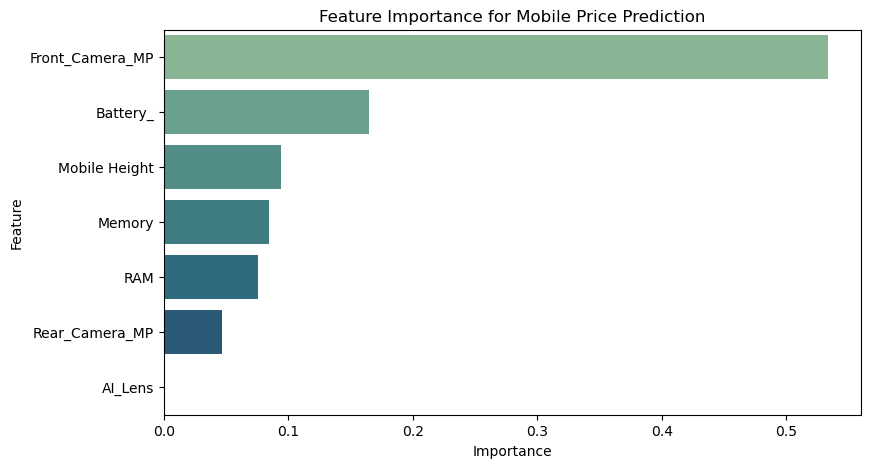

In [100]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

features = [
    "Memory",
    "RAM",
    "Battery_",
    "Mobile Height",
    "Rear_Camera_MP",
    "Front_Camera_MP",
    "AI_Lens"
]

X = df[features]
y = df["Prize"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

plt.figure(figsize=(9,5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature",
    hue="Feature",
    legend=False,
    palette="crest"
)

plt.title("Feature Importance for Mobile Price Prediction")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

### Multivariate analysis shows that mobile phone price is influenced by a combination of hardware specifications rather than a single feature. Memory and RAM have the strongest numerical relationships with price. Processor and model provide additional differentiation between price groups, while camera specifications contribute moderately. Battery capacity and mobile height have comparatively weaker effects. Overall, the combination of Memory, RAM, Processor, Model, and camera-related features provides the most useful information for mobile price prediction.

In [1]:
import pandas as pd
import tkinter as tk
from tkinter import ttk, messagebox

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline


# =========================================================
# 1. LOAD DATASET
# =========================================================


df = pd.read_excel(r"C:\Users\HP\Desktop\Python\Processed_Flipdata.xlsx")

df = df.drop(columns=["Unnamed: 0"], errors="ignore")

features = [
    "Model",
    "Colour",
    "Memory",
    "RAM",
    "Battery_",
    "Rear Camera",
    "Front Camera",
    "AI Lens",
    "Mobile Height",
    "Processor_"
]

target = "Prize"

df = df[features + [target]].dropna()

X = df[features]
y = df[target]


# =========================================================
# 2. PREPROCESSING
# =========================================================

categorical = [
    "Model",
    "Colour",
    "Rear Camera",
    "Front Camera",
    "AI Lens",
    "Processor_"
]

numerical = [
    "Memory",
    "RAM",
    "Battery_",
    "Mobile Height"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
        ("num", "passthrough", numerical)
    ]
)


# =========================================================
# 3. RANDOM FOREST MODEL
# =========================================================

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])


# =========================================================
# 4. TRAIN MODEL
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

model.fit(X_train, y_train)


# =========================================================
# 5. PREDICTION FUNCTION
# =========================================================

def predict_price():

    try:

        new_mobile = pd.DataFrame([{
            "Model": model_entry.get(),
            "Colour": colour_entry.get(),
            "Memory": float(memory_entry.get()),
            "RAM": float(ram_entry.get()),
            "Battery_": float(battery_entry.get()),
            "Rear Camera": rear_camera_entry.get(),
            "Front Camera": front_camera_entry.get(),
            "AI Lens": ai_lens_combo.get(),
            "Mobile Height": float(height_entry.get()),
            "Processor_": processor_entry.get()
        }])

        prediction = model.predict(new_mobile)[0]

        result_label.config(
            text=f"Predicted Price: ₹ {prediction:,.2f}"
        )

    except ValueError:
        messagebox.showerror(
            "Invalid Input",
            "Please enter valid numbers for Memory, RAM, Battery and Height."
        )

    except Exception as e:
        messagebox.showerror(
            "Error",
            str(e)
        )


# =========================================================
# 6. CLEAR FUNCTION
# =========================================================

def clear_fields():

    model_entry.delete(0, tk.END)
    colour_entry.delete(0, tk.END)
    memory_entry.delete(0, tk.END)
    ram_entry.delete(0, tk.END)
    battery_entry.delete(0, tk.END)
    rear_camera_entry.delete(0, tk.END)
    front_camera_entry.delete(0, tk.END)
    height_entry.delete(0, tk.END)

    ai_lens_combo.set("")
    processor_entry.delete(0, tk.END)

    result_label.config(text="Predicted Price: ₹ 0.00")


# =========================================================
# 7. TKINTER WINDOW
# =========================================================

root = tk.Tk()

root.title("Mobile Price Prediction System")

root.geometry("650x700")

root.resizable(False, False)


# =========================================================
# 8. TITLE
# =========================================================

title = tk.Label(
    root,
    text="Mobile Price Prediction",
    font=("Arial", 24, "bold")
)

title.pack(pady=20)


subtitle = tk.Label(
    root,
    text="Enter mobile specifications",
    font=("Arial", 12)
)

subtitle.pack(pady=5)


# =========================================================
# 9. INPUT FRAME
# =========================================================

frame = tk.Frame(root)

frame.pack(pady=10)


def add_input(row, text):

    label = tk.Label(
        frame,
        text=text,
        font=("Arial", 11)
    )

    label.grid(
        row=row,
        column=0,
        padx=10,
        pady=7,
        sticky="w"
    )

    entry = tk.Entry(
        frame,
        width=35,
        font=("Arial", 11)
    )

    entry.grid(
        row=row,
        column=1,
        padx=10,
        pady=7
    )

    return entry


# =========================================================
# 10. INPUT FIELDS
# =========================================================

model_entry = add_input(0, "Model")

colour_entry = add_input(1, "Colour")

memory_entry = add_input(2, "Memory (GB)")

ram_entry = add_input(3, "RAM (GB)")

battery_entry = add_input(4, "Battery (mAh)")

rear_camera_entry = add_input(5, "Rear Camera")

front_camera_entry = add_input(6, "Front Camera")


# AI Lens

tk.Label(
    frame,
    text="AI Lens",
    font=("Arial", 11)
).grid(
    row=7,
    column=0,
    padx=10,
    pady=7,
    sticky="w"
)

ai_lens_combo = ttk.Combobox(
    frame,
    values=["Yes", "No"],
    width=32,
    font=("Arial", 11),
    state="readonly"
)

ai_lens_combo.grid(
    row=7,
    column=1,
    padx=10,
    pady=7
)


height_entry = add_input(8, "Mobile Height")


processor_entry = add_input(9, "Processor")


# =========================================================
# 11. BUTTONS
# =========================================================

button_frame = tk.Frame(root)

button_frame.pack(pady=20)


predict_button = tk.Button(
    button_frame,
    text="Predict Price",
    command=predict_price,
    font=("Arial", 12, "bold"),
    padx=25,
    pady=10
)

predict_button.grid(
    row=0,
    column=0,
    padx=10
)


clear_button = tk.Button(
    button_frame,
    text="Clear",
    command=clear_fields,
    font=("Arial", 12, "bold"),
    padx=30,
    pady=10
)

clear_button.grid(
    row=0,
    column=1,
    padx=10
)


# =========================================================
# 12. RESULT
# =========================================================

result_label = tk.Label(
    root,
    text="Predicted Price: ₹ 0.00",
    font=("Arial", 20, "bold")
)

result_label.pack(pady=20)


# =========================================================
# 13. RUN APPLICATION
# =========================================================

root.mainloop()

### Final Conclusion: The Random Forest model successfully learns the relationship between mobile specifications and price. Memory, RAM, processor, model, and camera specifications are important factors in determining mobile prices. The model can predict the estimated price of a new mobile phone based on user-provided specifications, making it useful for pricing strategy and product planning.